In [1]:

import os
from pathlib import Path
from collections import Counter
ROOT = Path("/homes/nna272/Desktop/archive. (1)")

if not ROOT.exists():
    raise FileNotFoundError(f"Dataset directory not found: {ROOT}")

print("=" * 70)
print("DMID DATASET DIRECTORY INSPECTION")
print("=" * 70)
for current_root, dirs, files in os.walk(ROOT):
    relative = Path(current_root).relative_to(ROOT)

    depth = len(relative.parts)
    if depth > 4:
        dirs[:] = []
        continue

    indent = "    " * depth
    print(f"{indent}{Path(current_root).name}/")

    for filename in files[:8]:
        print(f"{indent}    {filename}")

tiff_files = list(ROOT.rglob("*.tif")) + list(ROOT.rglob("*.tiff"))

print("\nTotal TIFF files:", len(tiff_files))

# Count files by folder
folder_counts = Counter(
    str(p.parent.relative_to(ROOT))
    for p in tiff_files
)

print("\nTIFF files by folder:")
for folder, count in folder_counts.items():
    print(f"{folder}: {count}")

# Save inventory
inventory_path = ROOT / "tiff_inventory.csv"

import pandas as pd

pd.DataFrame({
    "filename": [p.name for p in tiff_files],
    "full_path": [str(p) for p in tiff_files],
    "parent_folder": [str(p.parent.relative_to(ROOT)) for p in tiff_files]
}).to_csv(inventory_path, index=False)

print("\nInventory saved:", inventory_path)


DMID DATASET DIRECTORY INSPECTION
archive. (1)/
    Metadata.xlsx
    tiff_inventory.csv
    task3_preprocessing/
    TIFF Images/
        TIFF Images/
            IMG073.tif
            IMG082.tif
            IMG460.tif
            IMG298.tif
            IMG273.tif
            IMG243.tif
            IMG391.tif
            IMG341.tif
    Pixel-level annotation/
        Pixel-level annotation/
            IMG073.tif
            IMG460.tif
            IMG298.tif
            IMG031.tif
            IMG101.tif
            IMG220.tif
            IMG061.tif
            IMG480.tif
    ROI Masks/
        ROI Masks/
            IMG073.tif
            IMG460.tif
            IMG298.tif
            IMG031.tif
            IMG101.tif
            IMG220.tif
            IMG061.tif
            IMG480.tif

Total TIFF files: 1049

TIFF files by folder:
TIFF Images/TIFF Images: 511
Pixel-level annotation/Pixel-level annotation: 269
ROI Masks/ROI Masks: 269

Inventory saved: /homes/nna272/Desktop/archive. (

In [2]:

from pathlib import Path
from collections import defaultdict

ROOT = Path("/homes/nna272/Desktop/archive. (1)")

categories = defaultdict(list)

for p in ROOT.rglob("*"):
    if not p.is_file():
        continue

    if p.suffix.lower() not in [".tif", ".tiff"]:
        continue

    folder = str(p.parent).lower()
    filename = p.name.lower()

    if "roi" in folder or "roi" in filename:
        categories["ROI Masks"].append(p)

    elif any(k in folder or k in filename
             for k in ["annotation", "annot", "groundtruth",
                       "ground_truth", "label", "mask"]):
        categories["Pixel-level Annotations"].append(p)

    else:
        categories["Potential Original Images"].append(p)

for category, files in categories.items():
    print("\n", "=" * 60)
    print(category, ":", len(files))

    for p in files[:15]:
        print(p.relative_to(ROOT))




Potential Original Images : 511
TIFF Images/TIFF Images/IMG073.tif
TIFF Images/TIFF Images/IMG082.tif
TIFF Images/TIFF Images/IMG460.tif
TIFF Images/TIFF Images/IMG298.tif
TIFF Images/TIFF Images/IMG273.tif
TIFF Images/TIFF Images/IMG243.tif
TIFF Images/TIFF Images/IMG391.tif
TIFF Images/TIFF Images/IMG341.tif
TIFF Images/TIFF Images/IMG375.tif
TIFF Images/TIFF Images/IMG121.tif
TIFF Images/TIFF Images/IMG265.tif
TIFF Images/TIFF Images/IMG031.tif
TIFF Images/TIFF Images/IMG101.tif
TIFF Images/TIFF Images/IMG018.tif
TIFF Images/TIFF Images/IMG217.tif

Pixel-level Annotations : 269
Pixel-level annotation/Pixel-level annotation/IMG073.tif
Pixel-level annotation/Pixel-level annotation/IMG460.tif
Pixel-level annotation/Pixel-level annotation/IMG298.tif
Pixel-level annotation/Pixel-level annotation/IMG031.tif
Pixel-level annotation/Pixel-level annotation/IMG101.tif
Pixel-level annotation/Pixel-level annotation/IMG220.tif
Pixel-level annotation/Pixel-level annotation/IMG061.tif
Pixel-level 

In [3]:

import tifffile
import numpy as np
from pathlib import Path

ROOT = Path("/homes/nna272/Desktop/archive. (1)")

tiff_files = sorted(
    list(ROOT.rglob("*.tif")) +
    list(ROOT.rglob("*.tiff"))
)

print("=" * 75)
print("TIFF IMAGE METADATA")
print("=" * 75)

for p in tiff_files[:20]:

    try:
        image = tifffile.imread(str(p))

        unique_values = np.unique(image)

        print("\nFile:", p.name)
        print("Folder:", p.parent.relative_to(ROOT))
        print("Shape:", image.shape)
        print("Data type:", image.dtype)
        print("Minimum:", image.min())
        print("Maximum:", image.max())
        print("Unique values:", len(unique_values))
        print("Sample unique values:", unique_values[:15])

    except Exception as e:
        print("Could not read:", p, "|", e)


TIFF IMAGE METADATA

File: IMG001.tif
Folder: Pixel-level annotation/Pixel-level annotation
Shape: (6000, 4751, 4)
Data type: uint8
Minimum: 0
Maximum: 255
Unique values: 234
Sample unique values: [ 0  6  7  8  9 10 11 12 13 14 15 16 17 18 19]

File: IMG008.tif
Folder: Pixel-level annotation/Pixel-level annotation
Shape: (6000, 4752, 4)
Data type: uint8
Minimum: 0
Maximum: 255
Unique values: 232
Sample unique values: [ 0  9 10 11 12 13 14 15 16 17 18 19 20 21 22]

File: IMG010.tif
Folder: Pixel-level annotation/Pixel-level annotation
Shape: (6000, 4750, 4)
Data type: uint8
Minimum: 0
Maximum: 255
Unique values: 222
Sample unique values: [ 0  3  4  5  6  7  8  9 10 11 12 13 14 15 16]

File: IMG011.tif
Folder: Pixel-level annotation/Pixel-level annotation
Shape: (6000, 4752, 4)
Data type: uint8
Minimum: 0
Maximum: 255
Unique values: 227
Sample unique values: [ 0  5  6  7  8  9 10 11 12 13 14 15 16 17 18]

File: IMG012.tif
Folder: Pixel-level annotation/Pixel-level annotation
Shape: (6000


FILE: IMG001.tif
Shape: (6000, 4751, 4)
Channel 0: Min = 0 Max = 237 Unique = 233 Mean = 48.477
Channel 1: Min = 0 Max = 233 Unique = 229 Mean = 48.216
Channel 2: Min = 0 Max = 233 Unique = 229 Mean = 48.183
Channel 3: Min = 255 Max = 255 Unique = 1 Mean = 255.0
Channels identical: False False False


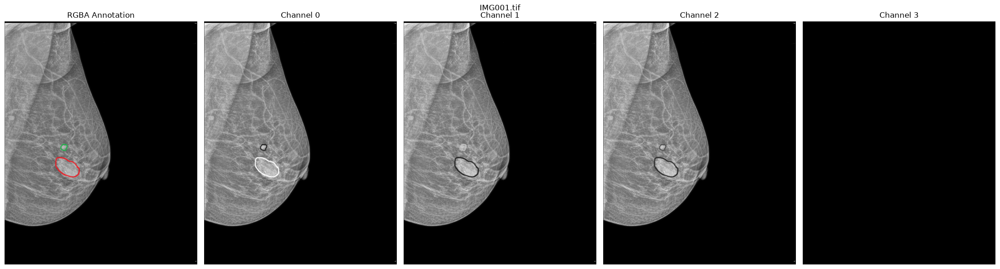


FILE: IMG008.tif
Shape: (6000, 4752, 4)
Channel 0: Min = 0 Max = 238 Unique = 231 Mean = 38.383
Channel 1: Min = 0 Max = 238 Unique = 231 Mean = 38.52
Channel 2: Min = 0 Max = 238 Unique = 231 Mean = 38.423
Channel 3: Min = 255 Max = 255 Unique = 1 Mean = 255.0
Channels identical: False False False


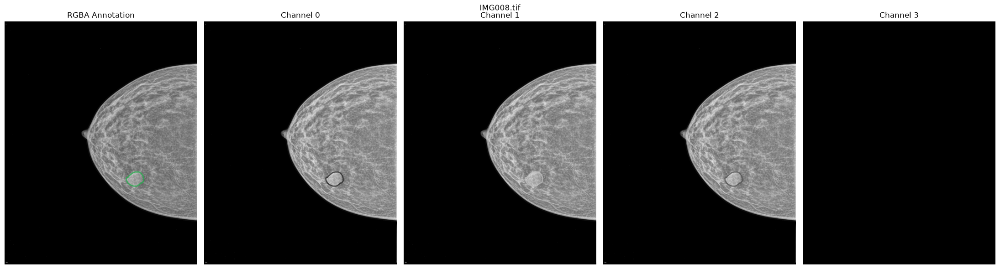


FILE: IMG010.tif
Shape: (6000, 4750, 4)
Channel 0: Min = 0 Max = 222 Unique = 221 Mean = 45.919
Channel 1: Min = 0 Max = 222 Unique = 221 Mean = 46.055
Channel 2: Min = 0 Max = 222 Unique = 221 Mean = 45.958
Channel 3: Min = 255 Max = 255 Unique = 1 Mean = 255.0
Channels identical: False False False


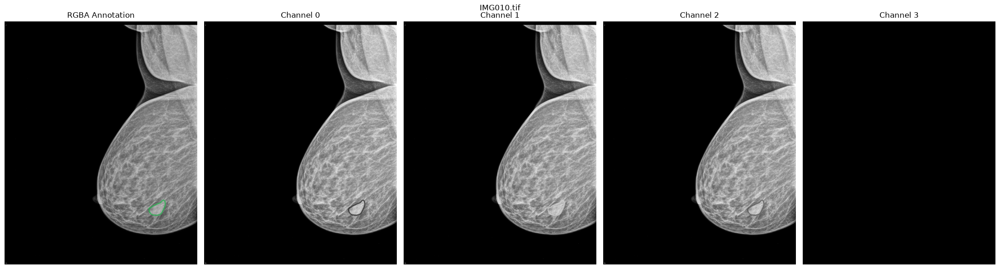

In [4]:
from pathlib import Path
import tifffile
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("/homes/nna272/Desktop/archive. (1)")
ANNOTATION_DIR = ROOT / "Pixel-level annotation" / "Pixel-level annotation"

sample_files = ["IMG001.tif", "IMG008.tif", "IMG010.tif"]

for filename in sample_files:

    path = ANNOTATION_DIR / filename
    arr = tifffile.imread(path)

    print("\n", "=" * 65)
    print("FILE:", filename)
    print("Shape:", arr.shape)

    for channel in range(arr.shape[-1]):
        ch = arr[:, :, channel]

        print(
            f"Channel {channel}:",
            "Min =", ch.min(),
            "Max =", ch.max(),
            "Unique =", len(np.unique(ch)),
            "Mean =", round(float(ch.mean()), 3)
        )

    print(
        "Channels identical:",
        np.array_equal(arr[:, :, 0], arr[:, :, 1]),
        np.array_equal(arr[:, :, 0], arr[:, :, 2]),
        np.array_equal(arr[:, :, 0], arr[:, :, 3])
    )

    # Downsample only for visualization
    scale = 6
    small = arr[::scale, ::scale, :]

    fig, axes = plt.subplots(1, 5, figsize=(22, 6))

    axes[0].imshow(small)
    axes[0].set_title("RGBA Annotation")

    for c in range(4):
        axes[c + 1].imshow(small[:, :, c], cmap="gray")
        axes[c + 1].set_title(f"Channel {c}")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()
    

Original image: (6000, 4751, 4) uint8
Annotation: (6000, 4751, 4) uint8
ROI: (6000, 4751, 4) uint8


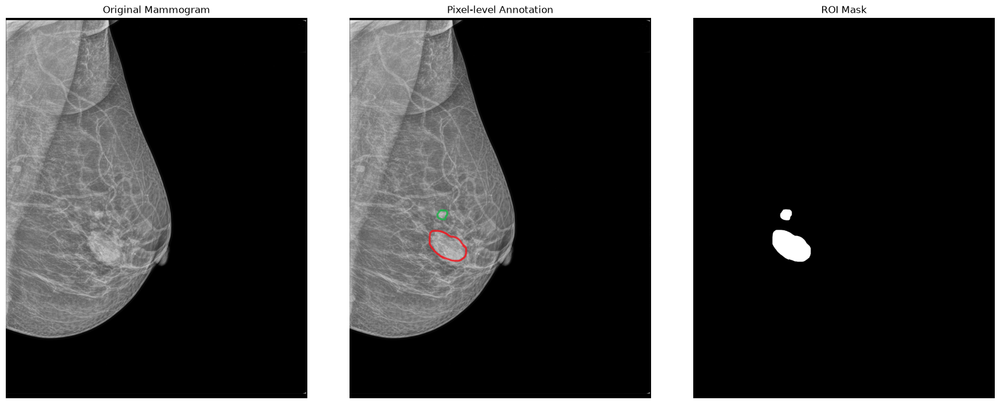

In [5]:
IMAGE_DIR = ROOT / "TIFF Images" / "TIFF Images"
ROI_DIR = ROOT / "ROI Masks" / "ROI Masks"

filename = "IMG001.tif"

image = tifffile.imread(IMAGE_DIR / filename)
annotation = tifffile.imread(ANNOTATION_DIR / filename)
roi = tifffile.imread(ROI_DIR / filename)

print("Original image:", image.shape, image.dtype)
print("Annotation:", annotation.shape, annotation.dtype)
print("ROI:", roi.shape, roi.dtype)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# Original mammogram
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Mammogram")

# Annotation in its native color representation
axes[1].imshow(annotation)
axes[1].set_title("Pixel-level Annotation")

# ROI mask
if roi.ndim == 2:
    axes[2].imshow(roi, cmap="gray")
else:
    axes[2].imshow(roi)

axes[2].set_title("ROI Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
annotation = tifffile.imread(
    ANNOTATION_DIR / "IMG001.tif"
)

alpha = annotation[:, :, 3]

print("Alpha channel statistics")
print("Minimum:", alpha.min())
print("Maximum:", alpha.max())
print("Unique values:", len(np.unique(alpha)))

values, counts = np.unique(alpha, return_counts=True)

print("\nMost frequent alpha values:")
for v, c in sorted(
    zip(values, counts),
    key=lambda x: x[1],
    reverse=True
)[:15]:
    print(f"Value {v}: {c} pixels")

Alpha channel statistics
Minimum: 255
Maximum: 255
Unique values: 1

Most frequent alpha values:
Value 255: 28506000 pixels


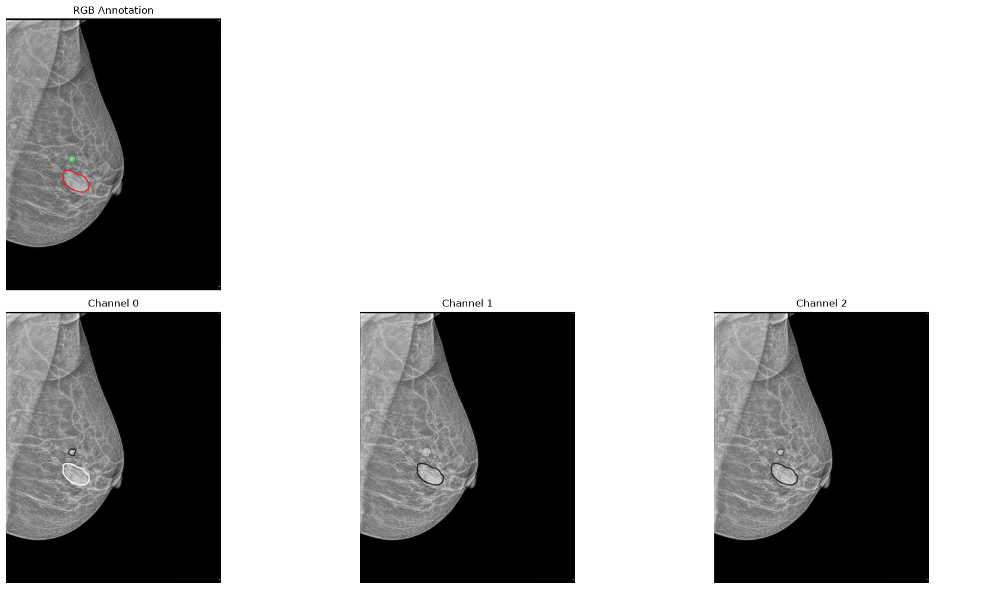

Most frequent RGB colors:
RGB: [0, 0, 0], Pixels: 17,692,785
RGB: [118, 118, 118], Pixels: 192,906
RGB: [120, 120, 120], Pixels: 192,637
RGB: [121, 121, 121], Pixels: 191,165
RGB: [123, 123, 123], Pixels: 190,842
RGB: [116, 116, 116], Pixels: 190,197
RGB: [115, 115, 115], Pixels: 188,686
RGB: [125, 125, 125], Pixels: 188,431
RGB: [127, 127, 127], Pixels: 184,997
RGB: [129, 129, 129], Pixels: 182,038
RGB: [113, 113, 113], Pixels: 181,789
RGB: [131, 131, 131], Pixels: 178,136
RGB: [112, 112, 112], Pixels: 177,087
RGB: [132, 132, 132], Pixels: 176,847
RGB: [119, 119, 119], Pixels: 175,275
RGB: [122, 122, 122], Pixels: 174,199
RGB: [117, 117, 117], Pixels: 174,120
RGB: [134, 134, 134], Pixels: 172,875
RGB: [124, 124, 124], Pixels: 172,488
RGB: [126, 126, 126], Pixels: 170,425


In [6]:
import tifffile
import numpy as np
import matplotlib.pyplot as plt

annotation = tifffile.imread(
    "/homes/nna272/Desktop/archive. (1)/Pixel-level annotation/Pixel-level annotation/IMG001.tif"
)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].imshow(annotation[:, :, :3])
axes[0, 0].set_title("RGB Annotation")

for i in range(3):
    axes[0, i + 1 if i < 2 else 0].axis("off")

for i in range(3):
    axes[1, i].imshow(annotation[:, :, i], cmap="gray")
    axes[1, i].set_title(f"Channel {i}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Inspect most frequent RGB colors
rgb = annotation[:, :, :3].reshape(-1, 3)

colors, counts = np.unique(
    rgb,
    axis=0,
    return_counts=True
)

indices = np.argsort(counts)[::-1][:20]

print("Most frequent RGB colors:")
for idx in indices:
    print(
        f"RGB: {colors[idx].tolist()}, "
        f"Pixels: {counts[idx]:,}"
    )

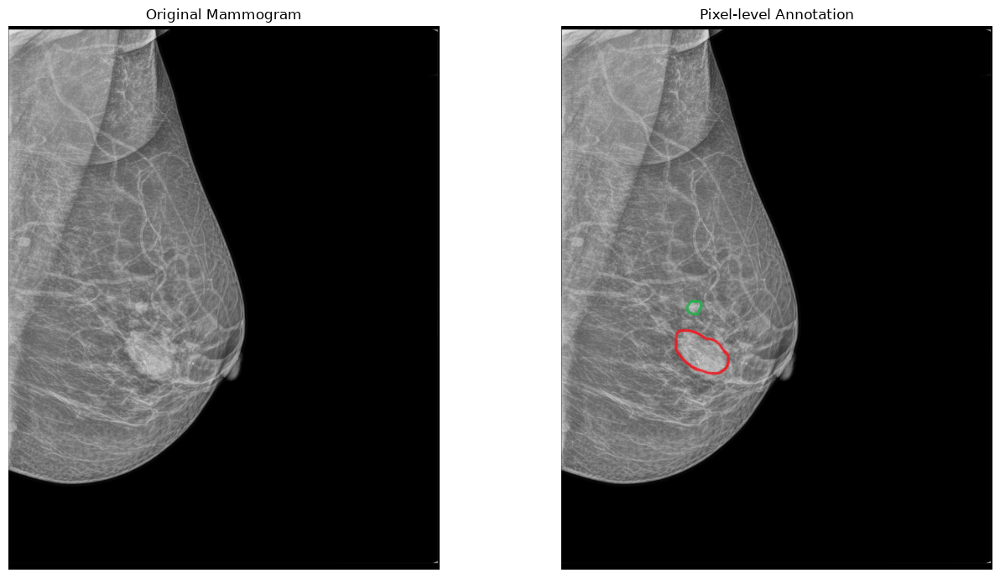

In [7]:
from pathlib import Path

ROOT = Path("/homes/nna272/Desktop/archive. (1)")

image = tifffile.imread(
    ROOT / "TIFF Images/TIFF Images/IMG001.tif"
)

annotation = tifffile.imread(
    ROOT / "Pixel-level annotation/Pixel-level annotation/IMG001.tif"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Mammogram")

axes[1].imshow(annotation[:, :, :3])
axes[1].set_title("Pixel-level Annotation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import tifffile
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/homes/nna272/Desktop/archive. (1)")

IMAGE_DIR = ROOT / "TIFF Images" / "TIFF Images"
ANNOTATION_DIR = ROOT / "Pixel-level annotation" / "Pixel-level annotation"
ROI_DIR = ROOT / "ROI Masks" / "ROI Masks"

filename = "IMG001.tif"

image = tifffile.imread(IMAGE_DIR / filename)
annotation = tifffile.imread(ANNOTATION_DIR / filename)
roi = tifffile.imread(ROI_DIR / filename)

rgb = annotation[:, :, :3]

print("Original image:", image.shape)
print("Annotation:", annotation.shape)
print("ROI:", roi.shape)

# Most frequent RGB colors
pixels = rgb.reshape(-1, 3)
colors, counts = np.unique(pixels, axis=0, return_counts=True)

indices = np.argsort(counts)[::-1][:20]

print("\nTop 20 RGB colors:")
for i in indices:
    print(f"{colors[i].tolist()} : {counts[i]:,} pixels")

# Channel statistics
for c, name in enumerate(["Red", "Green", "Blue"]):
    channel = rgb[:, :, c]
    print(
        f"\n{name}: min={channel.min()}, "
        f"max={channel.max()}, "
        f"unique={len(np.unique(channel))}"
    )

Original image: (6000, 4751, 4)
Annotation: (6000, 4751, 4)
ROI: (6000, 4751, 4)

Top 20 RGB colors:
[0, 0, 0] : 17,692,785 pixels
[118, 118, 118] : 192,906 pixels
[120, 120, 120] : 192,637 pixels
[121, 121, 121] : 191,165 pixels
[123, 123, 123] : 190,842 pixels
[116, 116, 116] : 190,197 pixels
[115, 115, 115] : 188,686 pixels
[125, 125, 125] : 188,431 pixels
[127, 127, 127] : 184,997 pixels
[129, 129, 129] : 182,038 pixels
[113, 113, 113] : 181,789 pixels
[131, 131, 131] : 178,136 pixels
[112, 112, 112] : 177,087 pixels
[132, 132, 132] : 176,847 pixels
[119, 119, 119] : 175,275 pixels
[122, 122, 122] : 174,199 pixels
[117, 117, 117] : 174,120 pixels
[134, 134, 134] : 172,875 pixels
[124, 124, 124] : 172,488 pixels
[126, 126, 126] : 170,425 pixels

Red: min=0, max=237, unique=233

Green: min=0, max=233, unique=229

Blue: min=0, max=233, unique=229


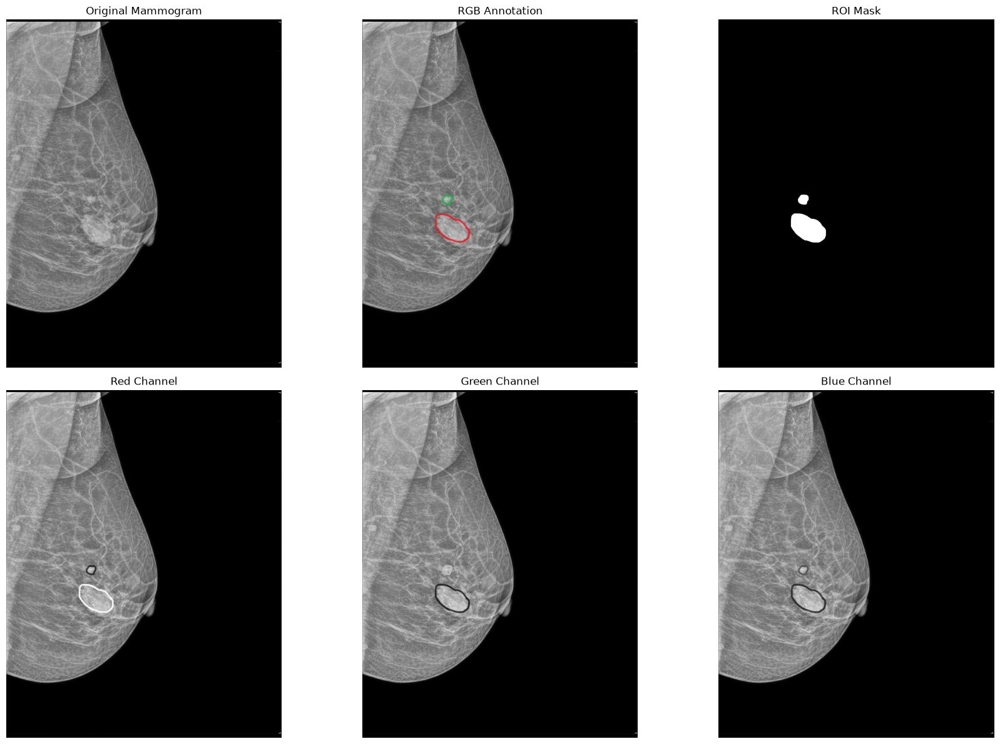

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

axes[0, 0].imshow(image, cmap="gray")
axes[0, 0].set_title("Original Mammogram")

axes[0, 1].imshow(rgb)
axes[0, 1].set_title("RGB Annotation")

axes[0, 2].imshow(roi, cmap="gray")
axes[0, 2].set_title("ROI Mask")

for c, name in enumerate(["Red", "Green", "Blue"]):
    axes[1, c].imshow(rgb[:, :, c], cmap="gray")
    axes[1, c].set_title(f"{name} Channel")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
print("Image and annotation dimensions match:",
      image.shape[:2] == annotation.shape[:2])

print("Image and ROI dimensions match:",
      image.shape[:2] == roi.shape[:2])

Image and annotation dimensions match: True
Image and ROI dimensions match: True


In [12]:
ROOT = Path("/homes/nna272/Desktop/archive. (1)")

paths = {
    "Original": ROOT / "TIFF Images/TIFF Images/IMG001.tif",
    "Annotation": ROOT / "Pixel-level annotation/Pixel-level annotation/IMG001.tif",
    "ROI": ROOT / "ROI Masks/ROI Masks/IMG001.tif"
}

arrays = {
    name: tifffile.imread(path)
    for name, path in paths.items()
}

for name, arr in arrays.items():

    print("\n", "=" * 60)
    print(name)

    for c in range(4):
        channel = arr[:, :, c]

        print(
            f"Channel {c}: "
            f"min={channel.min()}, "
            f"max={channel.max()}, "
            f"mean={channel.mean():.3f}, "
            f"unique={len(np.unique(channel))}"
        )

    print("RGB channels identical:",
          np.array_equal(arr[:, :, 0], arr[:, :, 1]) and
          np.array_equal(arr[:, :, 1], arr[:, :, 2]))

# original and annotation pixel values
original = arrays["Original"]
annotation = arrays["Annotation"]
roi = arrays["ROI"]

print("\nOriginal vs annotation")
print("Exact RGB equality:",
      np.array_equal(original[:, :, :3], annotation[:, :, :3]))

print("Mean absolute RGB difference:",
      np.mean(np.abs(
          original[:, :, :3].astype(np.float32) -
          annotation[:, :, :3].astype(np.float32)
      )))

print("\nAnnotation vs ROI")
print("Exact RGB equality:",
      np.array_equal(annotation[:, :, :3], roi[:, :, :3]))


Original
Channel 0: min=0, max=233, mean=48.374, unique=229
Channel 1: min=0, max=233, mean=48.374, unique=229
Channel 2: min=0, max=233, mean=48.374, unique=229
Channel 3: min=255, max=255, mean=255.000, unique=1
RGB channels identical: True

Annotation
Channel 0: min=0, max=237, mean=48.477, unique=233
Channel 1: min=0, max=233, mean=48.216, unique=229
Channel 2: min=0, max=233, mean=48.183, unique=229
Channel 3: min=255, max=255, mean=255.000, unique=1
RGB channels identical: False

ROI
Channel 0: min=0, max=255, mean=2.154, unique=2
Channel 1: min=0, max=255, mean=2.154, unique=2
Channel 2: min=0, max=255, mean=2.154, unique=2
Channel 3: min=255, max=255, mean=255.000, unique=1
RGB channels identical: True

Original vs annotation
Exact RGB equality: False
Mean absolute RGB difference: 0.19357178

Annotation vs ROI
Exact RGB equality: False


In [11]:
ROOT = Path("/homes/nna272/Desktop/archive. (1)")

image = tifffile.imread(
    ROOT / "TIFF Images/TIFF Images/IMG001.tif"
)

annotation = tifffile.imread(
    ROOT / "Pixel-level annotation/Pixel-level annotation/IMG001.tif"
)

roi = tifffile.imread(
    ROOT / "ROI Masks/ROI Masks/IMG001.tif"
)

# Extract grayscale 
original_gray = image[:, :, 0].astype(np.int16)

# Extract annotation RGB 
ann_rgb = annotation[:, :, :3].astype(np.int16)

# absolute differences from original
difference = np.abs(
    ann_rgb - original_gray[:, :, None]
)

# Maximum difference across RGB channels
difference_map = difference.max(axis=2)

print("Difference map statistics:")
print("Minimum:", difference_map.min())
print("Maximum:", difference_map.max())
print("Mean:", difference_map.mean())

for threshold in [0, 1, 2, 5, 10, 20]:
    mask = difference_map > threshold
    print(
        f"Threshold {threshold}: "
        f"{mask.sum():,} pixels "
        f"({mask.mean() * 100:.5f}%)"
    )

Difference map statistics:
Minimum: 0
Maximum: 173
Mean: 0.2433102504735845
Threshold 0: 66,160 pixels (0.23209%)
Threshold 1: 66,118 pixels (0.23194%)
Threshold 2: 66,091 pixels (0.23185%)
Threshold 5: 66,034 pixels (0.23165%)
Threshold 10: 65,906 pixels (0.23120%)
Threshold 20: 65,691 pixels (0.23045%)


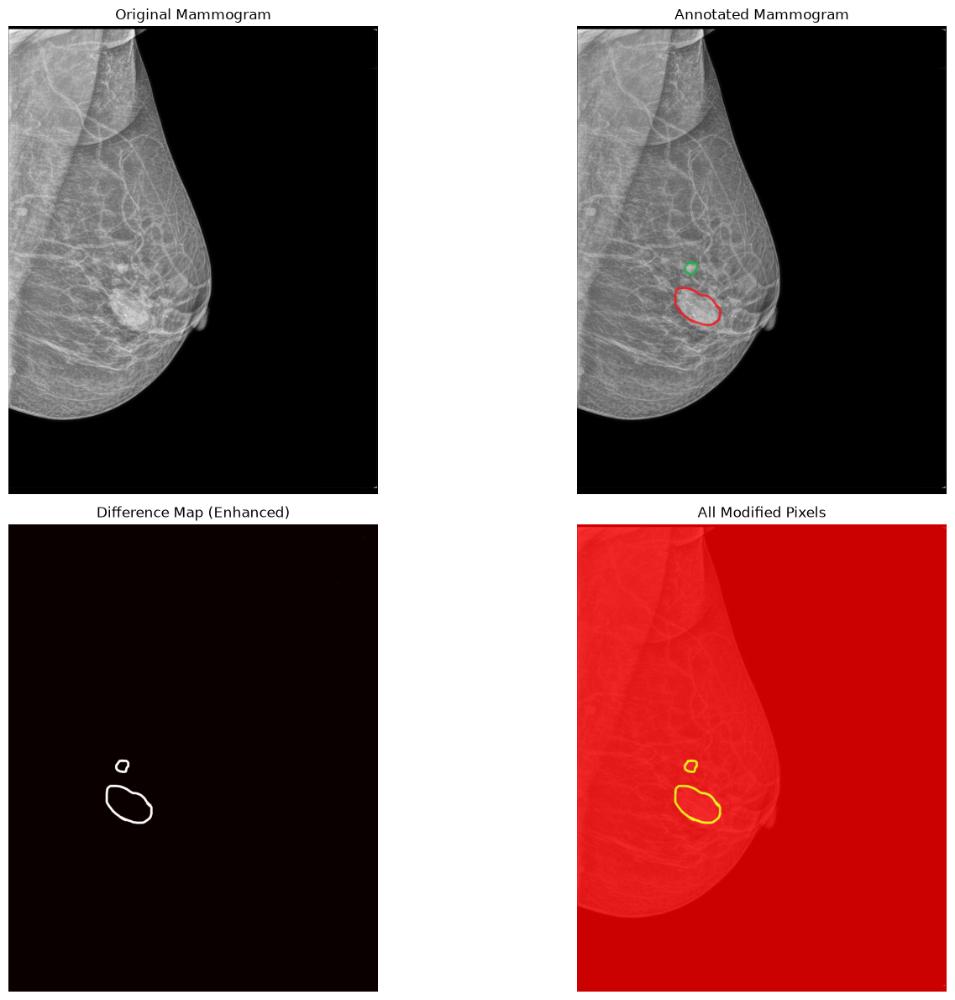

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0, 0].imshow(original_gray, cmap="gray")
axes[0, 0].set_title("Original Mammogram")

axes[0, 1].imshow(ann_rgb.astype(np.uint8))
axes[0, 1].set_title("Annotated Mammogram")

axes[1, 0].imshow(difference_map, cmap="hot", vmin=0, vmax=20)
axes[1, 0].set_title("Difference Map (Enhanced)")


axes[1, 1].imshow(original_gray, cmap="gray")
axes[1, 1].imshow(
    difference_map > 0,
    cmap="autumn",
    alpha=0.8
)
axes[1, 1].set_title("All Modified Pixels")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

ROI foreground pixels: 240777
ROI background pixels: 28265223
ROI coverage: 0.8447 %


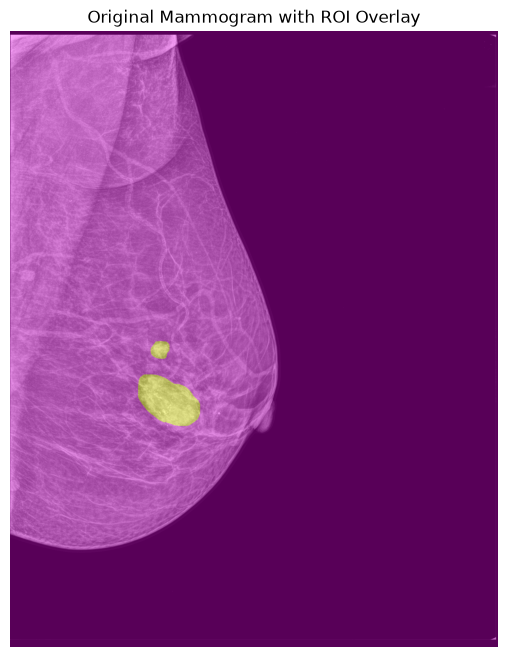

In [13]:
roi_binary = roi[:, :, 0] > 0

print("ROI foreground pixels:", roi_binary.sum())
print("ROI background pixels:", (~roi_binary).sum())
print("ROI coverage:", round(roi_binary.mean() * 100, 4), "%")

plt.figure(figsize=(8, 8))
plt.imshow(original_gray, cmap="gray")
plt.imshow(roi_binary, cmap="spring", alpha=0.35)
plt.title("Original Mammogram with ROI Overlay")
plt.axis("off")
plt.show()

In [14]:
ROOT = Path("/homes/nna272/Desktop/archive. (1)")

image = tifffile.imread(
    ROOT / "TIFF Images/TIFF Images/IMG001.tif"
)

annotation = tifffile.imread(
    ROOT / "Pixel-level annotation/Pixel-level annotation/IMG001.tif"
)

roi = tifffile.imread(
    ROOT / "ROI Masks/ROI Masks/IMG001.tif"
)

original_gray = image[:, :, 0].astype(np.int16)
ann_rgb = annotation[:, :, :3].astype(np.int16)

difference_map = np.abs(
    ann_rgb - original_gray[:, :, None]
).max(axis=2)

# Candidate annotation pixels
annotation_mask = difference_map > 20

# Binary ROI mask
roi_mask = roi[:, :, 0] > 0

intersection = annotation_mask & roi_mask
union = annotation_mask | roi_mask

print("Annotation foreground:", annotation_mask.sum())
print("ROI foreground:", roi_mask.sum())
print("Intersection:", intersection.sum())
print("Union:", union.sum())

print("Annotation inside ROI:",
      round(intersection.sum() / max(annotation_mask.sum(), 1) * 100, 3), "%")

print("ROI covered by annotation:",
      round(intersection.sum() / max(roi_mask.sum(), 1) * 100, 3), "%")

print("IoU:",
      round(intersection.sum() / max(union.sum(), 1), 5))

Annotation foreground: 65691
ROI foreground: 240777
Intersection: 65600
Union: 240868
Annotation inside ROI: 99.861 %
ROI covered by annotation: 27.245 %
IoU: 0.27235


In [15]:
from scipy import ndimage
def get_bbox(mask):
    rows, cols = np.where(mask)

    if len(rows) == 0:
        return None

    return (
        int(rows.min()), int(rows.max()),
        int(cols.min()), int(cols.max())
    )

for name, mask in [
    ("Annotation difference", annotation_mask),
    ("ROI", roi_mask),
    ("Intersection", intersection)
]:
    print(f"\n{name}")
    print("Bounding box:", get_bbox(mask))

# Connected components
labels, number = ndimage.label(annotation_mask)

sizes = np.bincount(labels.ravel())[1:]

print("\nAnnotation connected components:", number)
print("Largest component sizes:", np.sort(sizes)[-10:][::-1])


Annotation difference
Bounding box: (74, 3846, 1248, 4578)

ROI
Bounding box: (3020, 3846, 1248, 1851)

Intersection
Bounding box: (3020, 3846, 1248, 1851)

Annotation connected components: 31
Largest component sizes: [50966 14633    12    11     7     7     6     6     5     4]


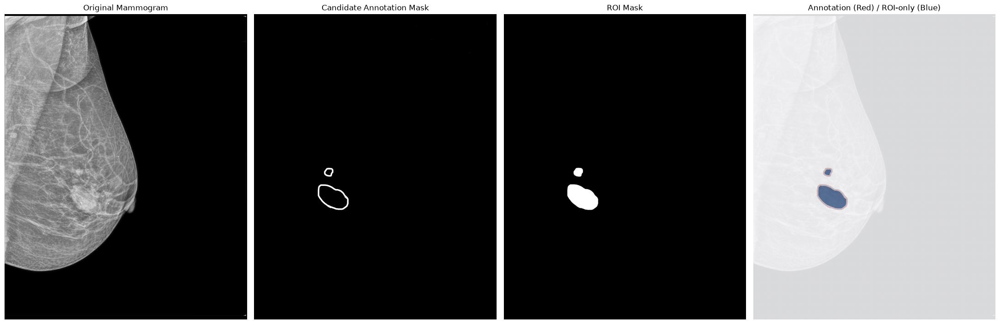

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(22, 7))

axes[0].imshow(original_gray, cmap="gray")
axes[0].set_title("Original Mammogram")

axes[1].imshow(annotation_mask, cmap="gray")
axes[1].set_title("Candidate Annotation Mask")

axes[2].imshow(roi_mask, cmap="gray")
axes[2].set_title("ROI Mask")

axes[3].imshow(original_gray, cmap="gray")
axes[3].imshow(annotation_mask, cmap="Reds", alpha=0.65)
axes[3].imshow(roi_mask & ~annotation_mask, cmap="Blues", alpha=0.65)
axes[3].set_title("Annotation (Red) / ROI-only (Blue)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

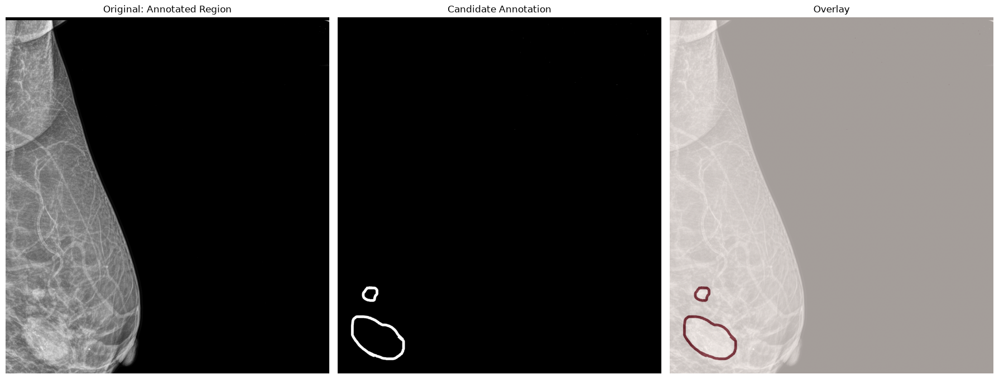

In [17]:
bbox = get_bbox(annotation_mask)

if bbox is not None:
    r1, r2, c1, c2 = bbox

    margin = 150

    r1 = max(0, r1 - margin)
    r2 = min(original_gray.shape[0], r2 + margin)
    c1 = max(0, c1 - margin)
    c2 = min(original_gray.shape[1], c2 + margin)

    fig, axes = plt.subplots(1, 3, figsize=(18, 7))

    axes[0].imshow(
        original_gray[r1:r2, c1:c2],
        cmap="gray"
    )
    axes[0].set_title("Original: Annotated Region")

    axes[1].imshow(
        annotation_mask[r1:r2, c1:c2],
        cmap="gray"
    )
    axes[1].set_title("Candidate Annotation")

    axes[2].imshow(
        original_gray[r1:r2, c1:c2],
        cmap="gray"
    )
    axes[2].imshow(
        annotation_mask[r1:r2, c1:c2],
        cmap="Reds",
        alpha=0.65
    )
    axes[2].set_title("Overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [18]:
ROOT = Path("/homes/nna272/Desktop/archive. (1)")

IMAGE_DIR = ROOT / "TIFF Images" / "TIFF Images"
ANNOTATION_DIR = ROOT / "Pixel-level annotation" / "Pixel-level annotation"
ROI_DIR = ROOT / "ROI Masks" / "ROI Masks"

OUTPUT_DIR = ROOT / "task3_preprocessing"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset directories initialized.")

Dataset directories initialized.


In [19]:
def get_tiff_files(folder):
    return {
        p.stem: p
        for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in [".tif", ".tiff"]
    }

images = get_tiff_files(IMAGE_DIR)
annotations = get_tiff_files(ANNOTATION_DIR)
rois = get_tiff_files(ROI_DIR)

image_ids = set(images)
annotation_ids = set(annotations)
roi_ids = set(rois)

common_ids = sorted(image_ids & annotation_ids & roi_ids)

print("Original images:", len(images))
print("Annotations:", len(annotations))
print("ROI masks:", len(rois))
print("Complete triplets:", len(common_ids))

print("Images without annotations:", len(image_ids - annotation_ids))
print("Annotations without original images:", len(annotation_ids - image_ids))
print("Images without ROI masks:", len(image_ids - roi_ids))

assert len(common_ids) > 0, "No matching image triplets found."

Original images: 511
Annotations: 269
ROI masks: 269
Complete triplets: 269
Images without annotations: 242
Annotations without original images: 0
Images without ROI masks: 242


In [20]:
import numpy as np

def to_grayscale(arr):
    """
    Converts 2D grayscale or multi-channel TIFF images
    into a 2D grayscale array.
    """
    arr = np.asarray(arr)

    if arr.ndim == 2:
        return arr

    elif arr.ndim == 3:
        if arr.shape[-1] >= 3:
            # RGB/RGBA: channels are identical for your
            # original mammograms, so channel 0 is sufficient.
            return arr[:, :, 0]

        elif arr.shape[-1] == 1:
            return arr[:, :, 0]

    raise ValueError(f"Unsupported image shape: {arr.shape}")


def to_rgb(arr):
    """
    Converts grayscale or multi-channel TIFF images
    into a three-channel representation.
    """
    arr = np.asarray(arr)

    if arr.ndim == 2:
        return np.repeat(arr[:, :, None], 3, axis=2)

    elif arr.ndim == 3:
        if arr.shape[-1] >= 3:
            return arr[:, :, :3]

        elif arr.shape[-1] == 1:
            return np.repeat(arr, 3, axis=2)

    raise ValueError(f"Unsupported annotation shape: {arr.shape}")

In [21]:
records = []

for image_id in common_ids:

    image = tifffile.imread(images[image_id])
    annotation = tifffile.imread(annotations[image_id])
    roi = tifffile.imread(rois[image_id])

    try:
        original_gray = to_grayscale(image)
        annotation_rgb = to_rgb(annotation)
        roi_gray = to_grayscale(roi)

        dimensions_match = (
            original_gray.shape ==
            annotation_rgb.shape[:2] ==
            roi_gray.shape
        )

        if not dimensions_match:
            records.append({
                "image_id": image_id,
                "dimensions_match": False,
                "error": "Dimension mismatch"
            })
            continue

        original_gray = original_gray.astype(np.int16)
        annotation_rgb = annotation_rgb.astype(np.int16)

        difference = np.abs(
            annotation_rgb - original_gray[:, :, None]
        ).max(axis=2)

        diff_1 = difference > 1
        diff_5 = difference > 5
        diff_10 = difference > 10
        diff_20 = difference > 20

        roi_mask = roi_gray > 0

        labels, number = ndimage.label(diff_20)
        component_sizes = np.bincount(labels.ravel())[1:]

        largest_component = (
            int(component_sizes.max())
            if len(component_sizes) > 0 else 0
        )

        intersection = diff_20 & roi_mask

        records.append({
            "image_id": image_id,
            "dimensions_match": True,
            "height": original_gray.shape[0],
            "width": original_gray.shape[1],
            "difference_pixels_t1": int(diff_1.sum()),
            "difference_pixels_t5": int(diff_5.sum()),
            "difference_pixels_t10": int(diff_10.sum()),
            "difference_pixels_t20": int(diff_20.sum()),
            "difference_percentage_t20": float(diff_20.mean() * 100),
            "roi_pixels": int(roi_mask.sum()),
            "roi_percentage": float(roi_mask.mean() * 100),
            "intersection_pixels": int(intersection.sum()),
            "annotation_inside_roi_percentage": float(
                intersection.sum() / max(diff_20.sum(), 1) * 100
            ),
            "connected_components": int(number),
            "largest_component_pixels": largest_component
        })

    except Exception as e:
        records.append({
            "image_id": image_id,
            "dimensions_match": False,
            "error": str(e)
        })

report = pd.DataFrame(records)

report_path = OUTPUT_DIR / "dmid_annotation_validation.csv"
report.to_csv(report_path, index=False)

print("Validation report saved:", report_path)
print("Total cases:", len(report))
print("Valid cases:", report["dimensions_match"].sum())
print("Invalid cases:", (~report["dimensions_match"]).sum())

print(report.head(10).to_string(index=False))

Validation report saved: /homes/nna272/Desktop/archive. (1)/task3_preprocessing/dmid_annotation_validation.csv
Total cases: 269
Valid cases: 269
Invalid cases: 0
image_id  dimensions_match  height  width  difference_pixels_t1  difference_pixels_t5  difference_pixels_t10  difference_pixels_t20  difference_percentage_t20  roi_pixels  roi_percentage  intersection_pixels  annotation_inside_roi_percentage  connected_components  largest_component_pixels
  IMG001              True    6000   4751                 66118                 66034                  65906                  65691                   0.230446      240777        0.844654                65600                         99.861473                    31                     50966
  IMG008              True    6000   4752                 36564                 36564                  36564                  36564                   0.128241      129018        0.452504                36556                         99.978121                 

In [25]:
import os
import copy
import random
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision import models, transforms
from torchvision.models import ResNet18_Weights

from scipy import ndimage
from sklearn.model_selection import train_test_split

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ROOT = Path("/homes/nna272/Desktop/archive. (1)")

IMAGE_DIR = ROOT / "TIFF Images" / "TIFF Images"
ANNOTATION_DIR = ROOT / "Pixel-level annotation" / "Pixel-level annotation"
ROI_DIR = ROOT / "ROI Masks" / "ROI Masks"

OUTPUT_DIR = ROOT / "task3_segmentation"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
CUDA available: True
GPU: NVIDIA GeForce RTX 3080


In [26]:
def load_grayscale_tiff(path):

    arr = tifffile.imread(path)

    if arr.ndim == 2:
        gray = arr

    elif arr.ndim == 3:
        gray = arr[:, :, 0]

    else:
        raise ValueError(
            f"Unsupported TIFF dimensions: {arr.shape}"
        )

    return gray.astype(np.float32)


def normalize_mammogram(image):

    image = image.astype(np.float32)

    # Robust percentile normalization
    low, high = np.percentile(image, [1, 99])

    image = np.clip(image, low, high)

    if high > low:
        image = (image - low) / (high - low)
    else:
        image = np.zeros_like(image)

    return image

In [27]:
def get_tiff_files(folder):

    return {
        p.stem: p
        for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in [".tif", ".tiff"]
    }


images = get_tiff_files(IMAGE_DIR)
annotations = get_tiff_files(ANNOTATION_DIR)
rois = get_tiff_files(ROI_DIR)

common_ids = sorted(
    set(images) & set(annotations) & set(rois)
)

manifest = pd.DataFrame([
    {
        "image_id": image_id,
        "image_path": str(images[image_id]),
        "annotation_path": str(annotations[image_id]),
        "roi_path": str(rois[image_id])
    }
    for image_id in common_ids
])

print("Complete image triplets:", len(manifest))

manifest.to_csv(
    OUTPUT_DIR / "dmid_manifest.csv",
    index=False
)

Complete image triplets: 269


In [28]:
def generate_candidate_mask(image_path, annotation_path):

    original = load_grayscale_tiff(image_path)

    annotation = tifffile.imread(annotation_path)

    if annotation.ndim == 2:
        annotation_rgb = np.repeat(
            annotation[:, :, None], 3, axis=2
        )
    else:
        annotation_rgb = annotation[:, :, :3]

    if original.shape != annotation_rgb.shape[:2]:
        raise ValueError("Image and annotation dimensions differ.")

    original_rgb = np.repeat(
        original[:, :, None], 3, axis=2
    )

    difference = np.abs(
        annotation_rgb.astype(np.float32) -
        original_rgb.astype(np.float32)
    ).max(axis=2)

    candidate_mask = difference > 20

    return candidate_mask.astype(np.uint8)

IMG001 Candidate foreground: 65691 ROI foreground: 240777


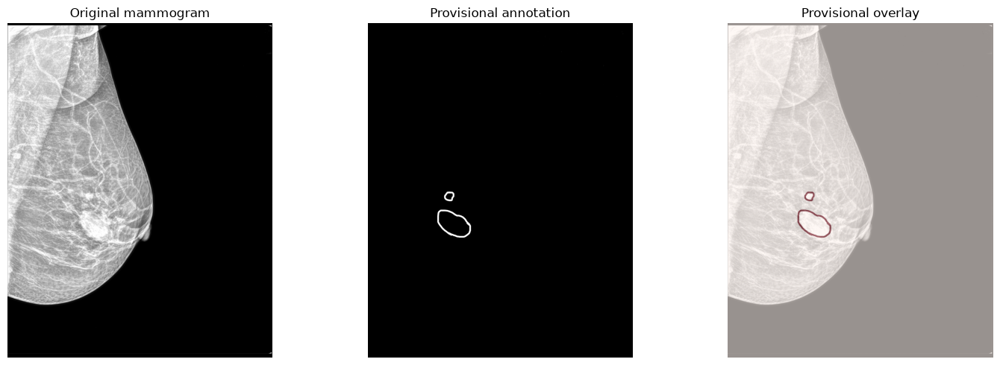

IMG008 Candidate foreground: 36564 ROI foreground: 129018


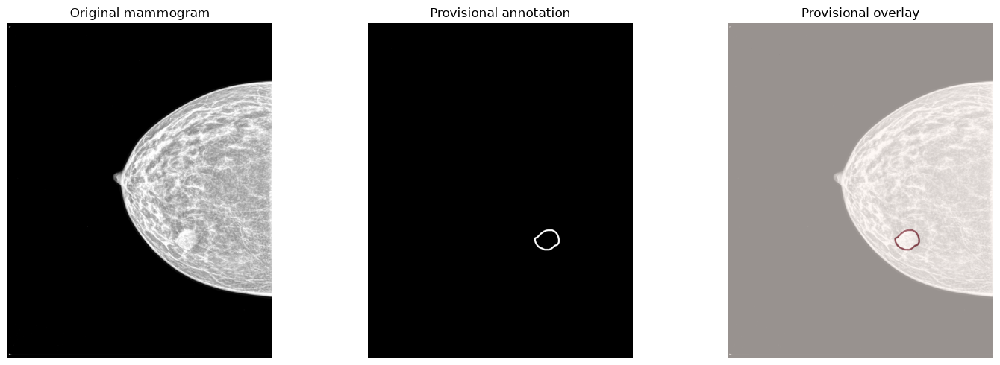

IMG010 Candidate foreground: 36020 ROI foreground: 109011


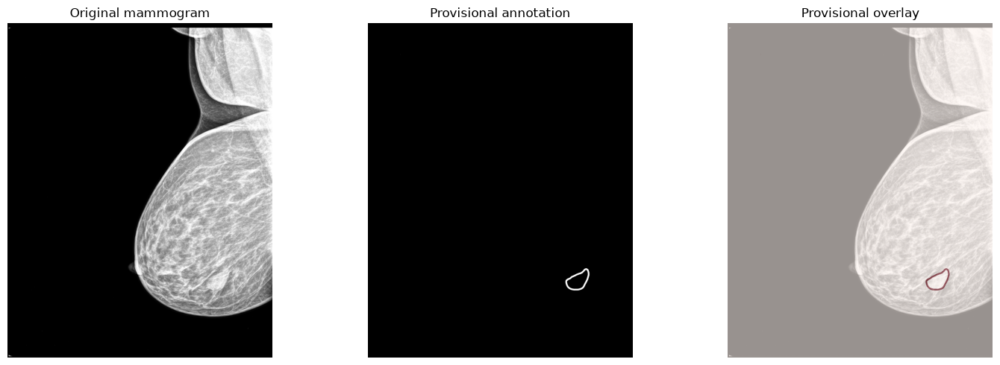

IMG011 Candidate foreground: 74575 ROI foreground: 289593


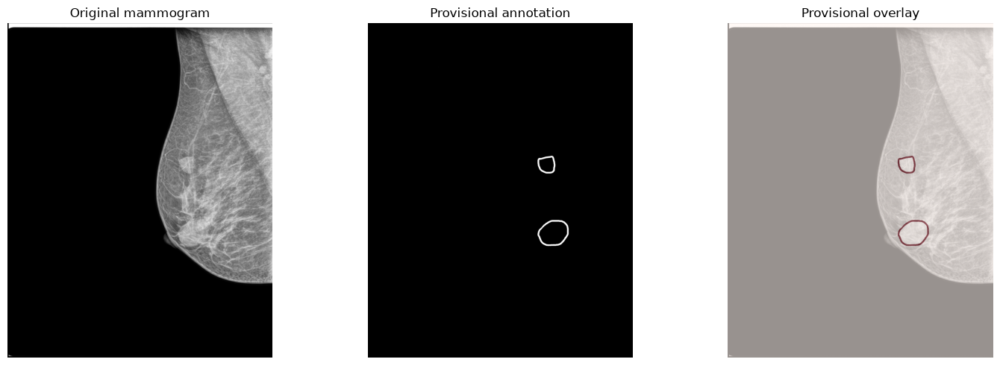

IMG012 Candidate foreground: 74009 ROI foreground: 288361


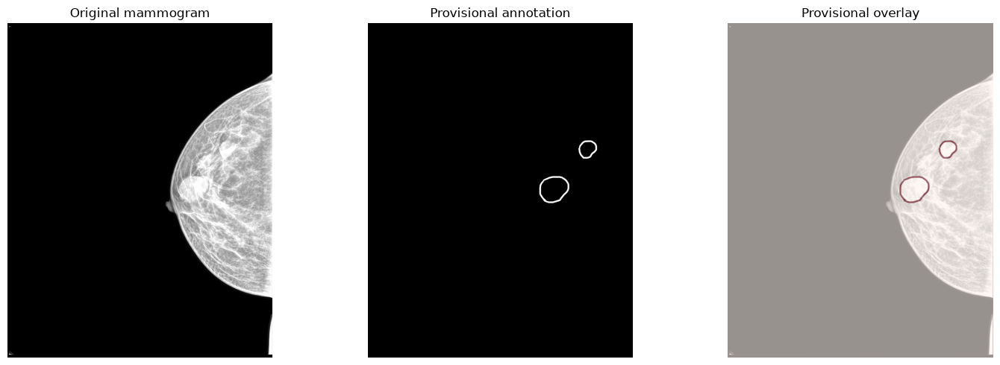

In [29]:
for idx in range(min(5, len(manifest))):

    row = manifest.iloc[idx]

    image = load_grayscale_tiff(row["image_path"])
    image = normalize_mammogram(image)

    candidate = generate_candidate_mask(
        row["image_path"],
        row["annotation_path"]
    )

    roi = load_grayscale_tiff(row["roi_path"]) > 0

    print(
        row["image_id"],
        "Candidate foreground:",
        candidate.sum(),
        "ROI foreground:",
        roi.sum()
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Original mammogram")

    axes[1].imshow(candidate, cmap="gray")
    axes[1].set_title("Provisional annotation")

    axes[2].imshow(image, cmap="gray")
    axes[2].imshow(candidate, cmap="Reds", alpha=0.6)
    axes[2].set_title("Provisional overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [30]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class ResNet18UNet(nn.Module):

    def __init__(self, pretrained=True):

        super().__init__()

        weights = (
            ResNet18_Weights.DEFAULT
            if pretrained else None
        )

        backbone = models.resnet18(weights=weights)

        # Encoder
        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        # Decoder
        self.up4 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )
        self.dec4 = ConvBlock(256 + 256, 256)

        self.up3 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )
        self.dec3 = ConvBlock(128 + 128, 128)

        self.up2 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )
        self.dec2 = ConvBlock(64 + 64, 64)

        self.up1 = nn.ConvTranspose2d(
            64, 64, kernel_size=2, stride=2
        )
        self.dec1 = ConvBlock(64 + 64, 64)

        self.up0 = nn.ConvTranspose2d(
            64, 32, kernel_size=2, stride=2
        )
        self.dec0 = ConvBlock(32, 32)

        self.final = nn.Conv2d(
            32, 1, kernel_size=1
        )

    def forward(self, x):

        input_size = x.shape[2:]

        # Encoder
        e0 = self.relu(self.bn1(self.conv1(x)))
        e1 = self.layer1(self.maxpool(e0))
        e2 = self.layer2(e1)
        e3 = self.layer3(e2)
        e4 = self.layer4(e3)

        # Decoder
        d4 = self.up4(e4)
        d4 = F.interpolate(
            d4, size=e3.shape[2:],
            mode="bilinear", align_corners=False
        )
        d4 = self.dec4(torch.cat([d4, e3], dim=1))

        d3 = self.up3(d4)
        d3 = F.interpolate(
            d3, size=e2.shape[2:],
            mode="bilinear", align_corners=False
        )
        d3 = self.dec3(torch.cat([d3, e2], dim=1))

        d2 = self.up2(d3)
        d2 = F.interpolate(
            d2, size=e1.shape[2:],
            mode="bilinear", align_corners=False
        )
        d2 = self.dec2(torch.cat([d2, e1], dim=1))

        d1 = self.up1(d2)
        d1 = F.interpolate(
            d1, size=e0.shape[2:],
            mode="bilinear", align_corners=False
        )
        d1 = self.dec1(torch.cat([d1, e0], dim=1))

        d0 = self.up0(d1)
        d0 = F.interpolate(
            d0, size=input_size,
            mode="bilinear", align_corners=False
        )
        d0 = self.dec0(d0)

        logits = self.final(d0)

        return logits

In [31]:
model = ResNet18UNet(pretrained=True).to(DEVICE)

dummy_input = torch.randn(
    2, 3, 512, 512
).to(DEVICE)

with torch.no_grad():
    dummy_output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Input shape: torch.Size([2, 3, 512, 512])
Output shape: torch.Size([2, 1, 512, 512])
Trainable parameters: 14343425


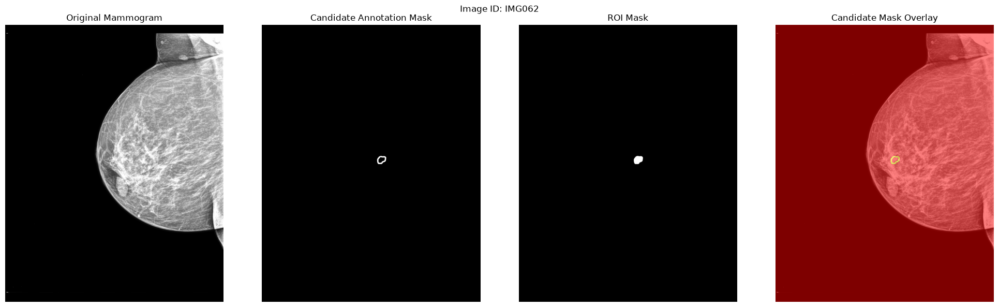

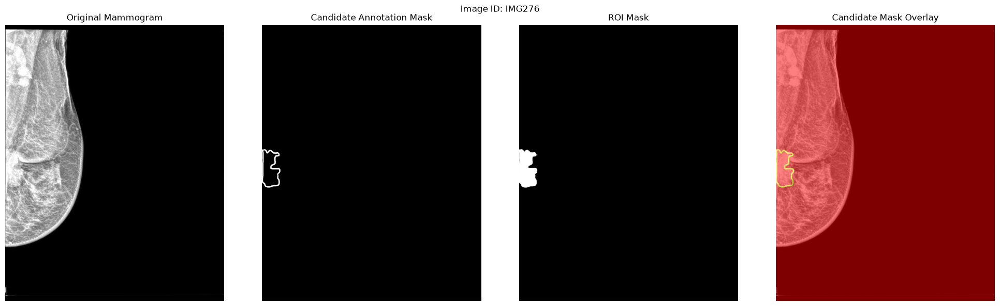

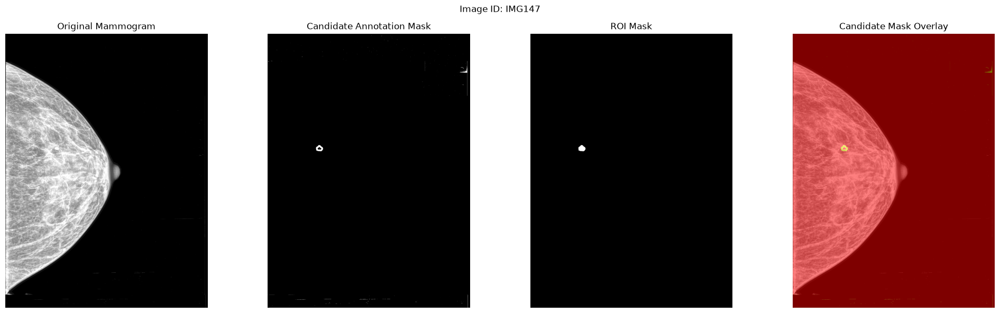

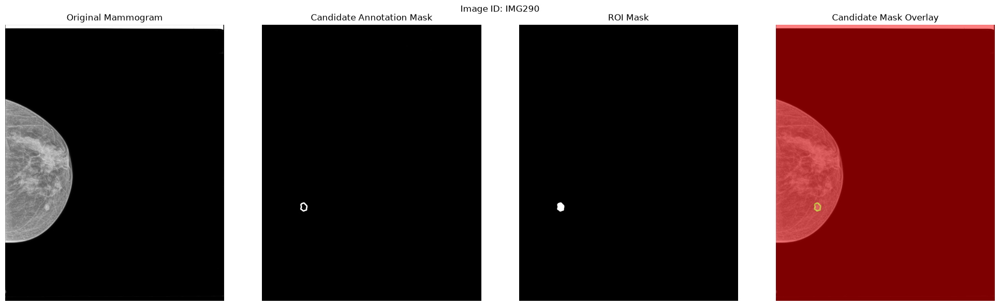

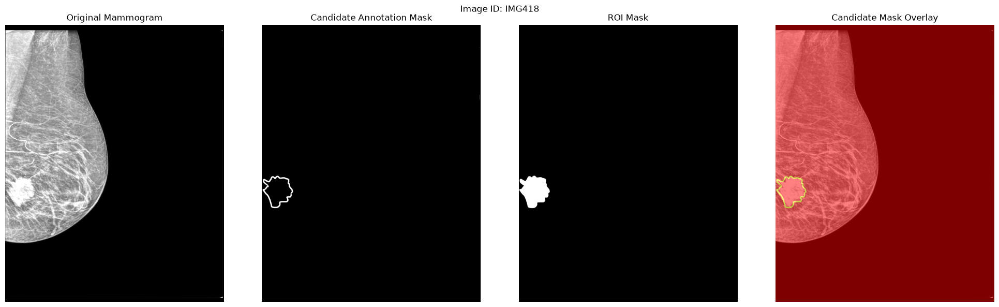

In [32]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tifffile
from pathlib import Path

def load_gray(path):
    arr = tifffile.imread(path)

    if arr.ndim == 2:
        return arr.astype(np.float32)

    return arr[:, :, 0].astype(np.float32)


def inspect_sample(row):
    image = load_gray(row["image_path"])

    annotation = tifffile.imread(row["annotation_path"])
    if annotation.ndim == 2:
        annotation_rgb = np.repeat(
            annotation[:, :, None], 3, axis=2
        )
    else:
        annotation_rgb = annotation[:, :, :3]

    roi = tifffile.imread(row["roi_path"])
    if roi.ndim == 3:
        roi = roi[:, :, 0]

    image_rgb = np.repeat(image[:, :, None], 3, axis=2)

    difference = np.abs(
        annotation_rgb.astype(np.float32)
        - image_rgb.astype(np.float32)
    ).max(axis=2)

    candidate_mask = difference > 20

    # Normalize image for visualization
    low, high = np.percentile(image, [1, 99])
    image_vis = np.clip(image, low, high)
    image_vis = (image_vis - low) / (high - low + 1e-8)

    fig, axes = plt.subplots(1, 4, figsize=(20, 6))

    axes[0].imshow(image_vis, cmap="gray")
    axes[0].set_title("Original Mammogram")

    axes[1].imshow(candidate_mask, cmap="gray")
    axes[1].set_title("Candidate Annotation Mask")

    axes[2].imshow(roi > 0, cmap="gray")
    axes[2].set_title("ROI Mask")

    axes[3].imshow(image_vis, cmap="gray")
    axes[3].imshow(candidate_mask, cmap="autumn", alpha=0.5)
    axes[3].set_title("Candidate Mask Overlay")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(f"Image ID: {row['image_id']}")
    plt.tight_layout()
    plt.show()


sample_rows = manifest.sample(
    n=min(5, len(manifest)),
    random_state=42
)

for _, row in sample_rows.iterrows():
    inspect_sample(row)

IMG062: ROI pixels=27,565, contour pixels=15,523, ROI coverage=0.0969%


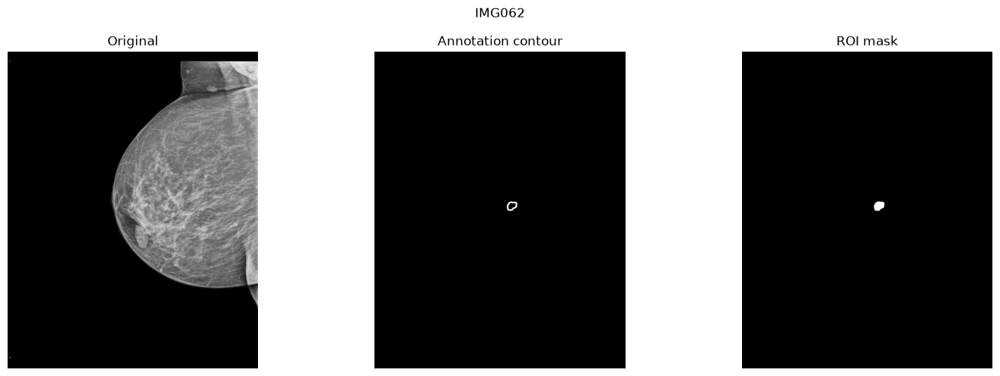

IMG472: ROI pixels=214,709, contour pixels=54,131, ROI coverage=0.7543%


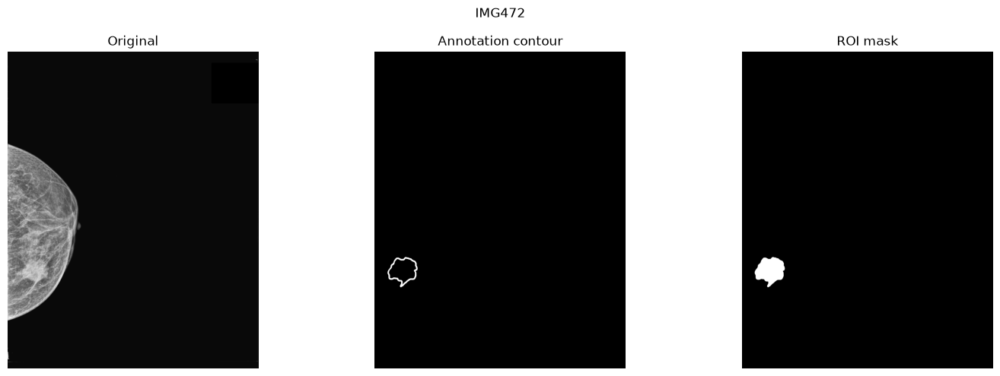

IMG465: ROI pixels=357,033, contour pixels=61,795, ROI coverage=1.2565%


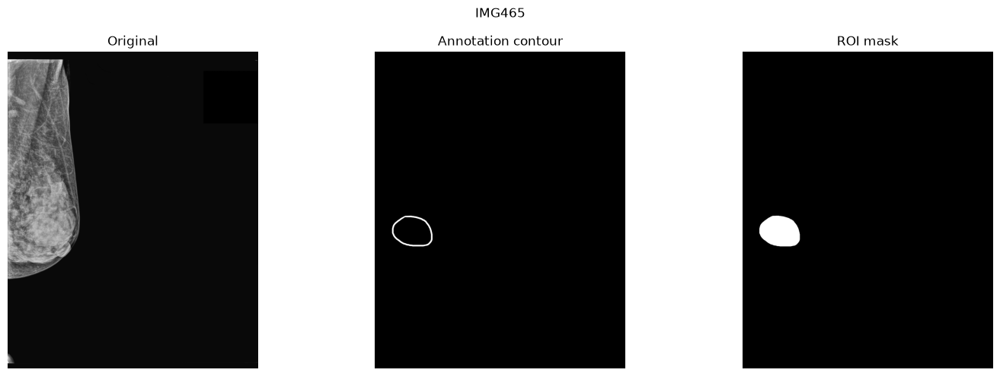

IMG061: ROI pixels=125,027, contour pixels=54,720, ROI coverage=0.4393%


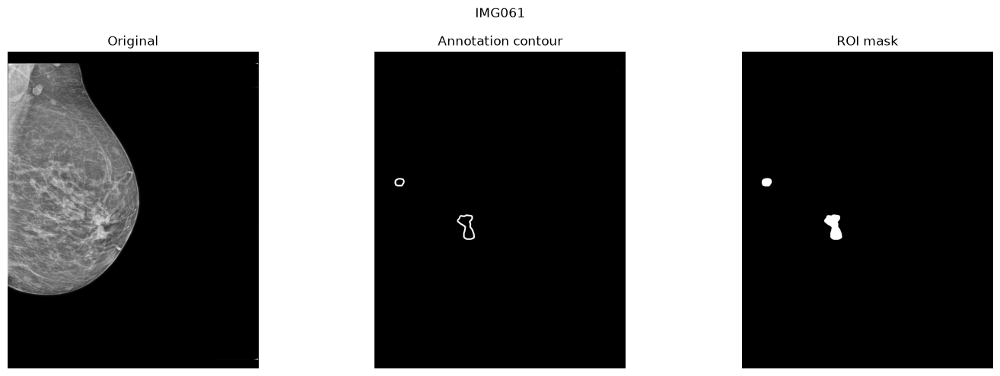

IMG456: ROI pixels=883,483, contour pixels=126,783, ROI coverage=3.1039%


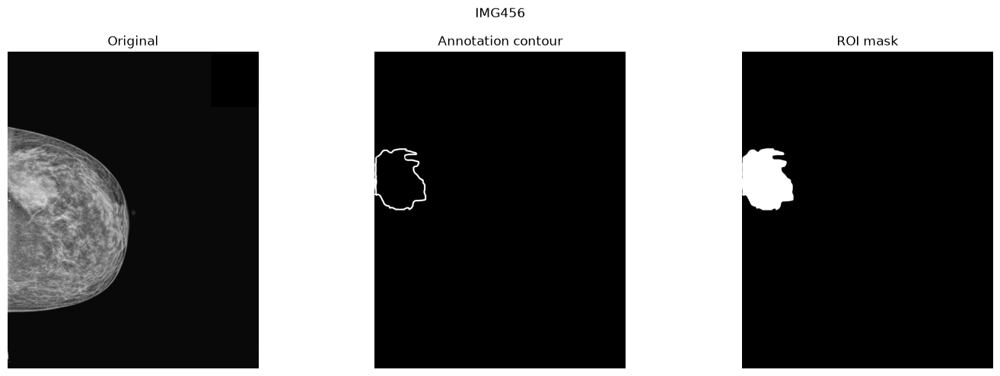

IMG413: ROI pixels=718,005, contour pixels=131,219, ROI coverage=2.5214%


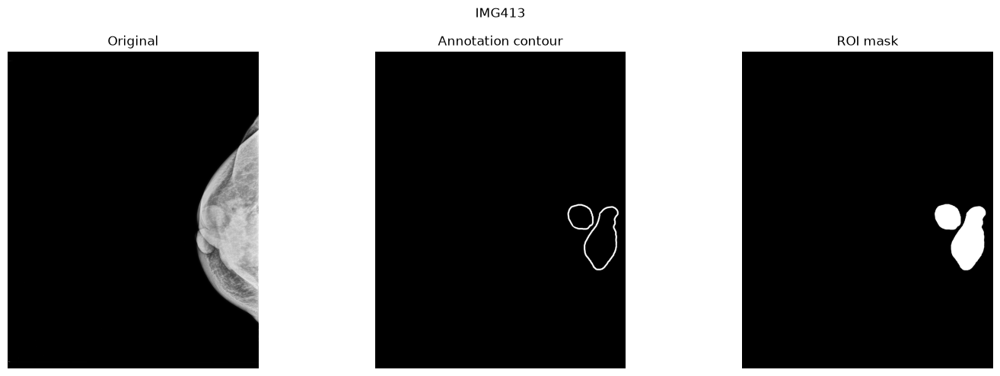

IMG446: ROI pixels=458,995, contour pixels=139,024, ROI coverage=1.6122%


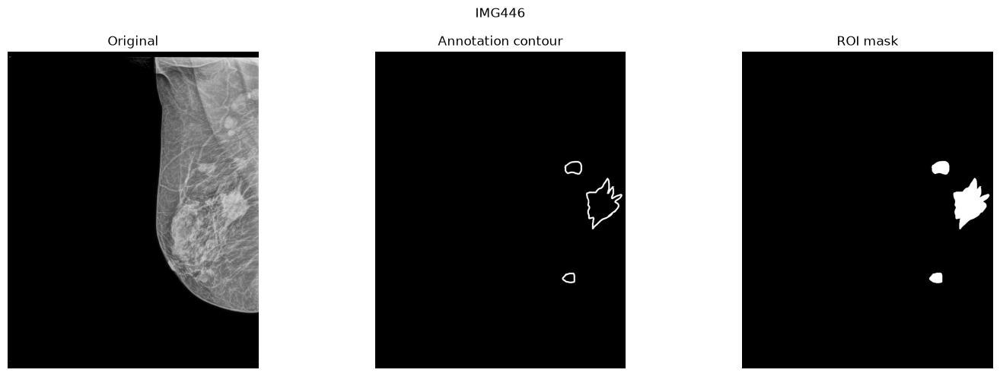

IMG043: ROI pixels=357,044, contour pixels=96,067, ROI coverage=2.1197%


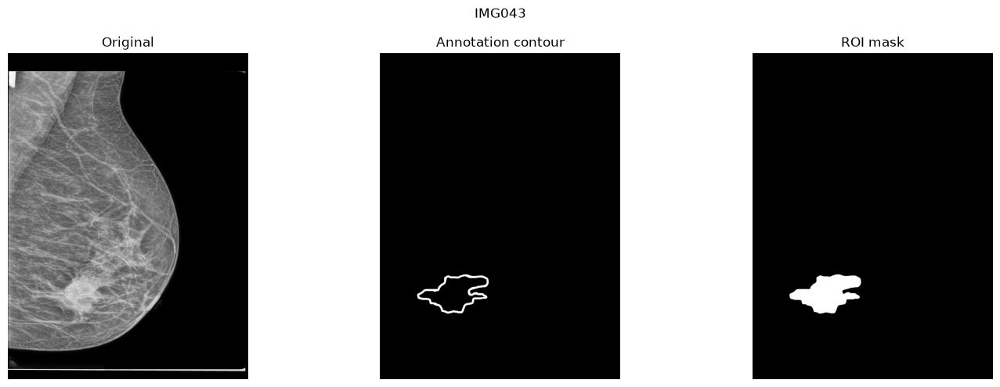

IMG322: ROI pixels=338,117, contour pixels=103,276, ROI coverage=1.1871%


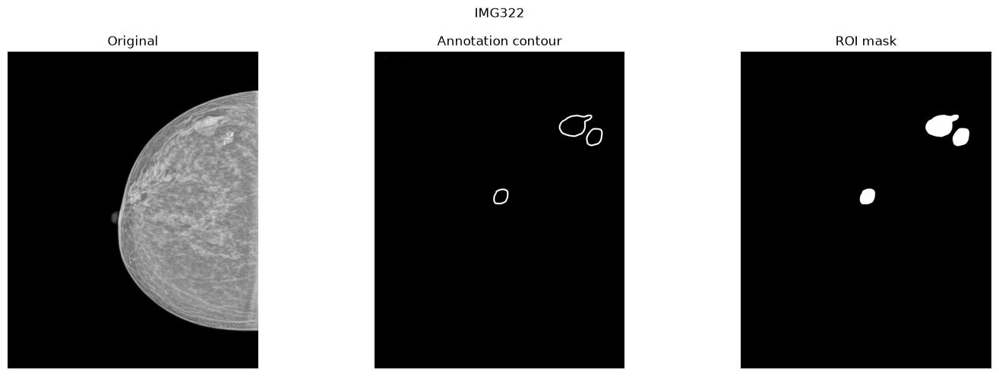

IMG355: ROI pixels=57,382, contour pixels=41,623, ROI coverage=0.2014%


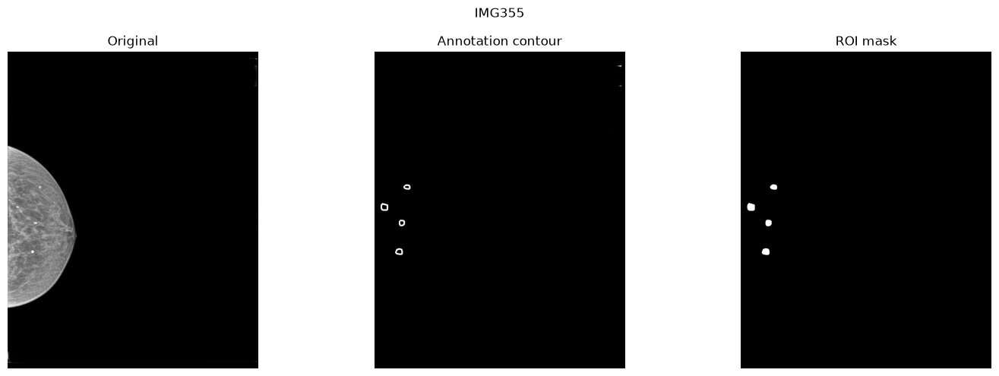

In [33]:
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt

def inspect_mask(row):
    image = load_gray(row["image_path"])
    annotation = tifffile.imread(row["annotation_path"])
    roi = tifffile.imread(row["roi_path"])

    if annotation.ndim == 3:
        annotation = annotation[:, :, :3]

    if roi.ndim == 3:
        roi = roi[:, :, 0]

    # Convert annotation to a contour candidate
    if annotation.ndim == 3:
        original_rgb = np.repeat(
            image[:, :, None], 3, axis=2
        )
        difference = np.abs(
            annotation.astype(np.float32)
            - original_rgb.astype(np.float32)
        ).max(axis=2)
        contour = difference > 20
    else:
        contour = np.abs(
            annotation.astype(np.float32) - image
        ) > 20

    roi_binary = roi > 0

    print(
        f"{row['image_id']}: "
        f"ROI pixels={roi_binary.sum():,}, "
        f"contour pixels={contour.sum():,}, "
        f"ROI coverage={roi_binary.mean()*100:.4f}%"
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Original")

    axes[1].imshow(contour, cmap="gray")
    axes[1].set_title("Annotation contour")

    axes[2].imshow(roi_binary, cmap="gray")
    axes[2].set_title("ROI mask")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(row["image_id"])
    plt.tight_layout()
    plt.show()


sample = manifest.sample(
    n=min(10, len(manifest)),
    random_state=123
)

for _, row in sample.iterrows():
    inspect_mask(row)

In [34]:
import numpy as np
import pandas as pd
import tifffile
from scipy import ndimage

def check_alignment(row):
    image = load_gray(row["image_path"])

    annotation = tifffile.imread(row["annotation_path"])
    roi = tifffile.imread(row["roi_path"])

    if annotation.ndim == 3:
        annotation_rgb = annotation[:, :, :3].astype(np.float32)
        image_rgb = np.repeat(image[:, :, None], 3, axis=2)

        difference = np.abs(
            annotation_rgb - image_rgb
        ).max(axis=2)

        contour = difference > 20
    else:
        contour = (
            np.abs(annotation.astype(np.float32) - image) > 20
        )

    if roi.ndim == 3:
        roi = roi[:, :, 0]

    roi_binary = roi > 0
    contour = contour.astype(bool)

    # Extract boundary of the ROI
    boundary = roi_binary & ~ndimage.binary_erosion(
        roi_binary
    )

    # Measure distances from contour pixels to ROI boundary
    distance_map = ndimage.distance_transform_edt(~boundary)

    contour_distances = distance_map[contour]

    if len(contour_distances) == 0:
        return {
            "image_id": row["image_id"],
            "roi_pixels": int(roi_binary.sum()),
            "contour_pixels": 0,
            "mean_distance": np.nan,
            "within_5px": np.nan
        }

    return {
        "image_id": row["image_id"],
        "roi_pixels": int(roi_binary.sum()),
        "contour_pixels": int(contour.sum()),
        "mean_distance": float(contour_distances.mean()),
        "median_distance": float(np.median(contour_distances)),
        "within_5px": float(
            np.mean(contour_distances <= 5) * 100
        ),
        "within_10px": float(
            np.mean(contour_distances <= 10) * 100
        )
    }


alignment_results = pd.DataFrame([
    check_alignment(row)
    for _, row in manifest.iterrows()
])

print(alignment_results.head(20).to_string(index=False))

print("\nSummary:")
print(
    alignment_results[
        ["mean_distance", "median_distance",
         "within_5px", "within_10px"]
    ].describe()
)

alignment_results.to_csv(
    "task3_segmentation/annotation_roi_alignment.csv",
    index=False
)

image_id  roi_pixels  contour_pixels  mean_distance  median_distance  within_5px  within_10px
  IMG001      240777           65691      18.530245        13.038405   21.623967    39.742126
  IMG008      129018           36564      14.794844        13.601471   20.815556    38.092112
  IMG010      109011           36020      14.829403        13.416408   21.060522    38.711827
  IMG011      289593           74575      13.932959        13.601471   20.948039    38.368086
  IMG012      288361           74009      13.789888        13.453624   21.005553    38.649353
  IMG014      214587           53476      13.713480        13.341664   20.803725    38.680904
  IMG015      307841           73984      13.769745        13.416408   20.915333    38.708369
  IMG021      112181           33111      13.579110        13.038405   21.684637    39.530670
  IMG024      199151           89133      14.374887        13.892444   20.706136    38.221534
  IMG025      147650          215044    2909.384507      421

OSError: Cannot save file into a non-existent directory: 'task3_segmentation'

In [35]:
from pathlib import Path

output_dir = Path("task3_segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

alignment_results.to_csv(
    output_dir / "annotation_roi_alignment.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


10 worst-aligned samples:
image_id  roi_pixels  contour_pixels  mean_distance  median_distance  within_5px  within_10px
  IMG025      147650          215044    2909.384507      4212.971517    7.808169    13.950168
  IMG480      477666          244305    2348.999204      3782.169351    8.293731    15.390188
  IMG479      125812          189429    2783.105221      3548.154027    4.977063     9.183388
  IMG147       10003           20093    1714.028103      2673.538853    9.983576    17.876873
  IMG444      946381          173000      23.902553        22.847319   12.642197    23.387861
  IMG443     1132290          202906      24.111777        22.472205   12.514169    23.317694
  IMG429      199985          108084      23.251450        20.808652   14.158432    26.038081
  IMG205       10999           13063    1833.324909        20.396078   15.762076    28.209447
  IMG048      427487           92624      26.890025        17.000000   16.842287    31.146355
  IMG449      205504           763

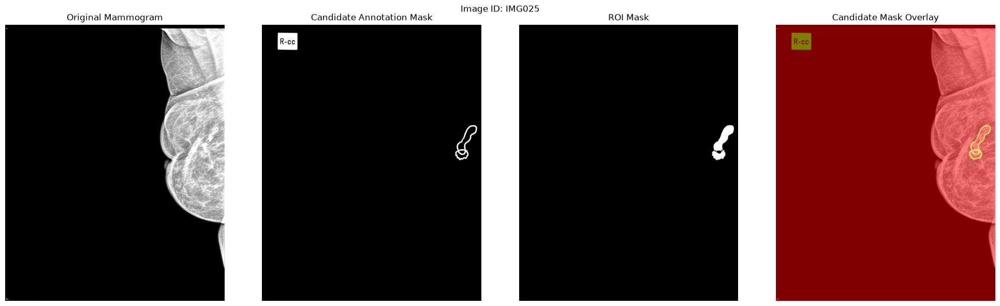

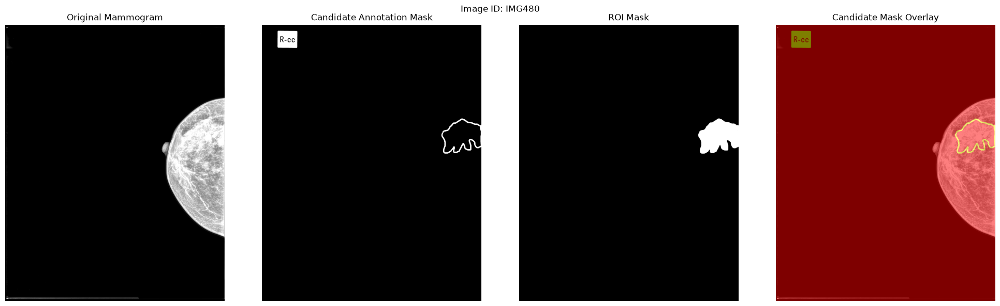

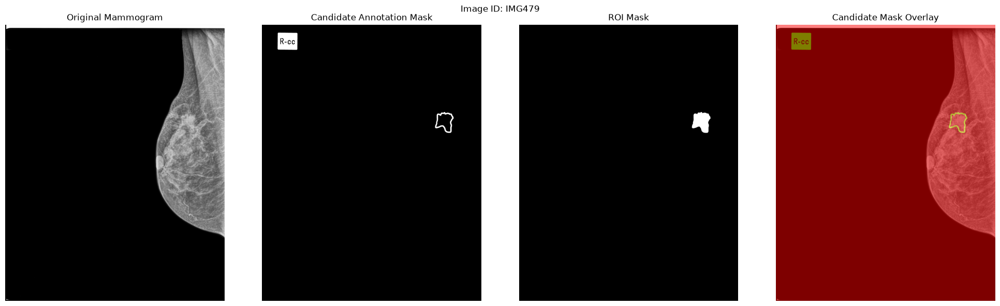

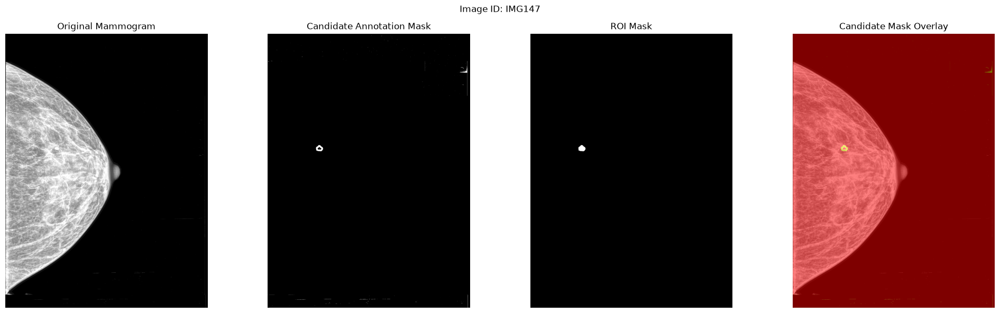

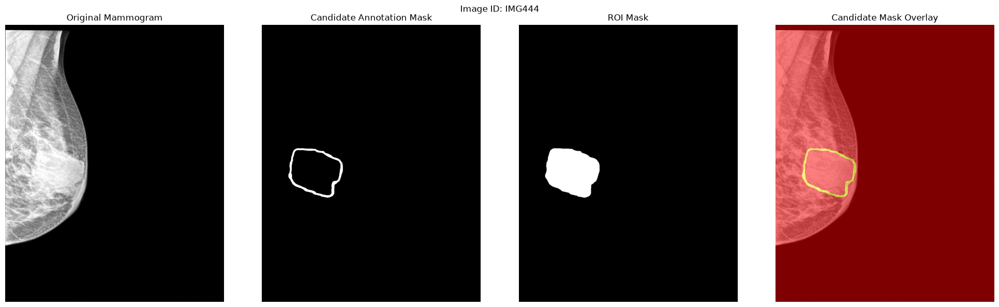

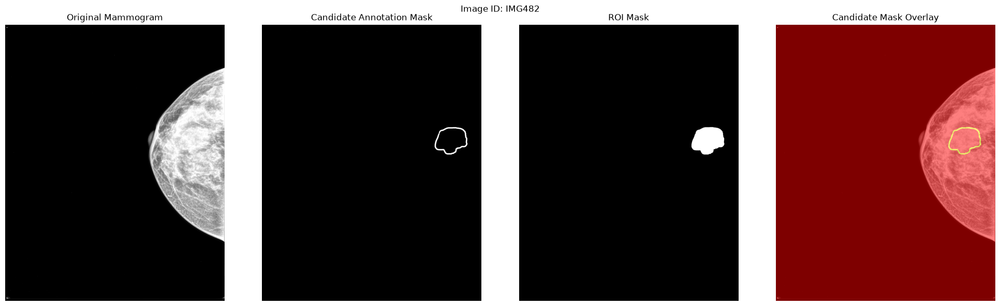

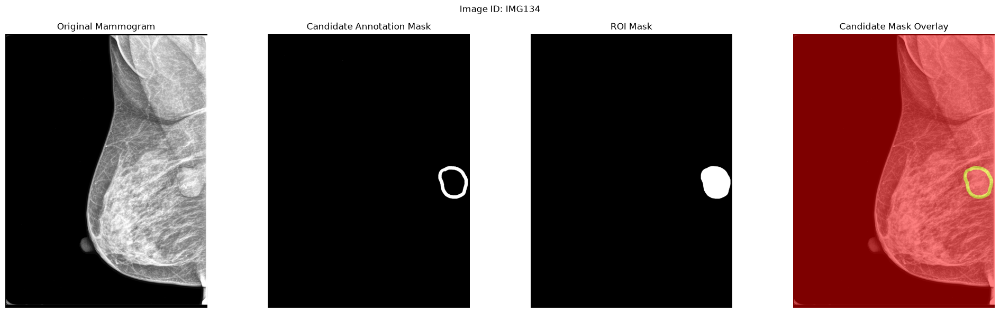

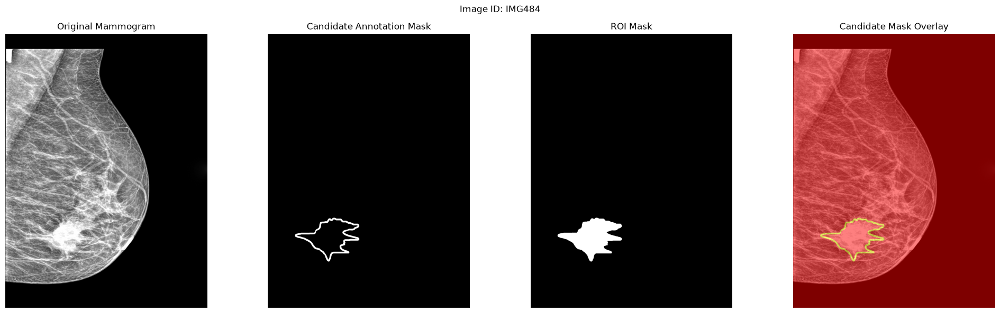

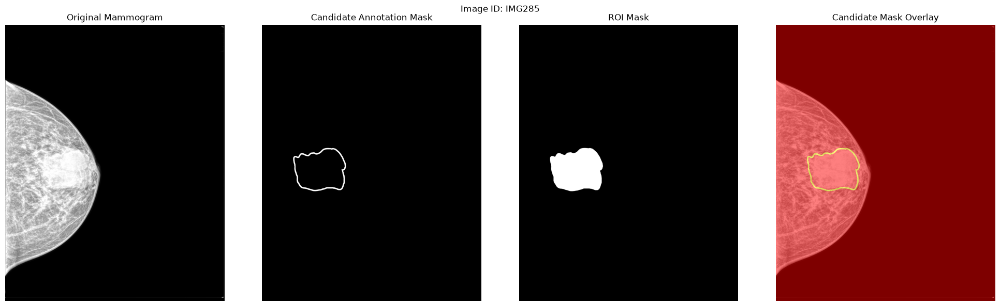

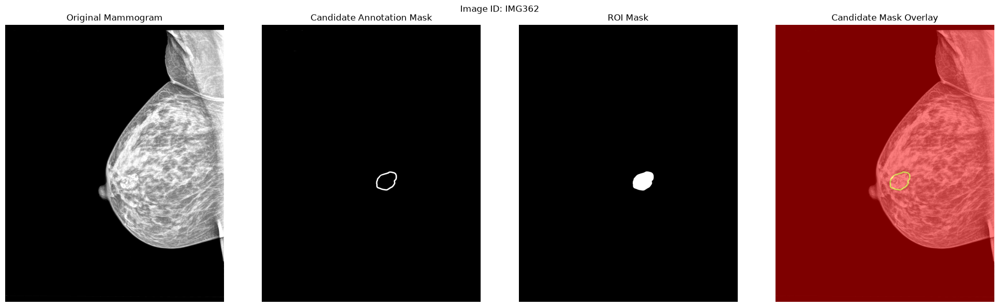

In [36]:
# Sort by median distance
worst_samples = alignment_results.sort_values(
    "median_distance",
    ascending=False
)

print("10 worst-aligned samples:")
print(
    worst_samples[
        [
            "image_id",
            "roi_pixels",
            "contour_pixels",
            "mean_distance",
            "median_distance",
            "within_5px",
            "within_10px"
        ]
    ].head(10).to_string(index=False)
)

# Inspect the worst five and five typical samples
worst_ids = worst_samples.head(5)["image_id"].tolist()

typical_ids = (
    alignment_results
    .assign(
        median_difference=lambda x:
        abs(x["median_distance"] - x["median_distance"].median())
    )
    .sort_values("median_difference")
    .head(5)["image_id"]
    .tolist()
)

inspect_ids = worst_ids + typical_ids

for image_id in inspect_ids:
    row = manifest.loc[
        manifest["image_id"] == image_id
    ].iloc[0]

    inspect_sample(row)

In [37]:
import cv2
import numpy as np
import tifffile

def compare_masks(row):
    image = load_gray(row["image_path"])

    annotation = tifffile.imread(row["annotation_path"])
    roi = tifffile.imread(row["roi_path"])

    if annotation.ndim == 3:
        original_rgb = np.repeat(
            image[:, :, None], 3, axis=2
        )

        difference = np.abs(
            annotation[:, :, :3].astype(np.float32)
            - original_rgb.astype(np.float32)
        ).max(axis=2)

        contour = (difference > 20).astype(np.uint8)
    else:
        contour = (
            np.abs(annotation.astype(np.float32) - image) > 20
        ).astype(np.uint8)

    if roi.ndim == 3:
        roi = roi[:, :, 0]

    roi_binary = (roi > 0).astype(np.uint8)

    # Fill closed contours
    contours, _ = cv2.findContours(
        contour,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    filled = np.zeros_like(contour)
    cv2.drawContours(
        filled,
        contours,
        -1,
        1,
        thickness=cv2.FILLED
    )

    intersection = np.logical_and(
        filled > 0, roi_binary > 0
    ).sum()

    dice = (
        2 * intersection /
        (filled.sum() + roi_binary.sum() + 1e-8)
    )

    iou = (
        intersection /
        (np.logical_or(filled > 0, roi_binary > 0).sum() + 1e-8)
    )

    return {
        "image_id": row["image_id"],
        "filled_contour_pixels": int(filled.sum()),
        "roi_pixels": int(roi_binary.sum()),
        "dice": float(dice),
        "iou": float(iou)
    }


overlap_results = pd.DataFrame([
    compare_masks(row)
    for _, row in manifest.iterrows()
])

print(overlap_results.describe())

print(
    overlap_results.sort_values("dice").head(15)
)

       filled_contour_pixels    roi_pixels        dice         iou
count           2.690000e+02  2.690000e+02  269.000000  269.000000
mean            4.556719e+05  4.532982e+05    0.991286    0.986423
std             9.749123e+05  9.753582e+05    0.051040    0.073591
min             1.059800e+04  1.000300e+04    0.513724    0.345645
25%             1.115990e+05  1.103380e+05    0.999234    0.998470
50%             2.644410e+05  2.563990e+05    0.999686    0.999372
75%             4.261770e+05  4.263850e+05    0.999826    0.999653
max             1.064694e+07  1.064704e+07    0.999984    0.999968
    image_id  filled_contour_pixels  roi_pixels      dice       iou
115   IMG275                 139764       48368  0.513724  0.345645
245   IMG479                 283241      125812  0.614810  0.443846
79    IMG147                  22149       10003  0.618064  0.447245
9     IMG025                 311800      147650  0.642129  0.472894
99    IMG205                  15827       10999  0.814807

In [38]:
import os
import pandas as pd

qc = overlap_results.copy()

qc["qc_status"] = "PASS"

qc.loc[
    qc["dice"] < 0.95,
    "qc_status"
] = "REVIEW"

qc.loc[
    qc["dice"] < 0.80,
    "qc_status"
] = "CRITICAL_REVIEW"

print(qc["qc_status"].value_counts())

print("\nSamples requiring review:")
print(
    qc[qc["qc_status"] != "PASS"]
    .sort_values("dice")
    .to_string(index=False)
)

os.makedirs("task3_segmentation", exist_ok=True)

qc.to_csv(
    "task3_segmentation/mask_quality_report.csv",
    index=False
)

qc_status
PASS               263
CRITICAL_REVIEW      4
REVIEW               2
Name: count, dtype: int64

Samples requiring review:
image_id  filled_contour_pixels  roi_pixels     dice      iou       qc_status
  IMG275                 139764       48368 0.513724 0.345645 CRITICAL_REVIEW
  IMG479                 283241      125812 0.614810 0.443846 CRITICAL_REVIEW
  IMG147                  22149       10003 0.618064 0.447245 CRITICAL_REVIEW
  IMG025                 311800      147650 0.642129 0.472894 CRITICAL_REVIEW
  IMG205                  15827       10999 0.814807 0.687488          REVIEW
  IMG480                 635164      477666 0.858203 0.751625          REVIEW


In [39]:
import pandas as pd

metadata_path = (
    "/homes/nna272/Desktop/archive. (1)/Metadata.xlsx"
)

xls = pd.ExcelFile(metadata_path)

print("Sheets:", xls.sheet_names)

for sheet in xls.sheet_names:
    df = pd.read_excel(metadata_path, sheet_name=sheet)

    print("\nSheet:", sheet)
    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())

    print(df.head(3).to_string(index=False))

Sheets: ['Sheet1']

Sheet: Sheet1
Shape: (677, 8)
Columns:
['1st column:', ' Image reference number.', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7']
 1st column:  Image reference number. Unnamed: 2 Unnamed: 3 Unnamed: 4  Unnamed: 5  Unnamed: 6 Unnamed: 7
         NaN                      NaN        NaN        NaN        NaN         NaN         NaN        NaN
2nd column:         Mammogram View :         NaN        NaN        NaN         NaN         NaN        NaN
         NaN                      NaN        NaN      CCRT         NaN         NaN         NaN        NaN


In [40]:
import os
import copy
import random
import numpy as np
import pandas as pd
import tifffile
import cv2
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUTPUT_DIR = Path("task3_segmentation")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )

Device: cuda
GPU: NVIDIA GeForce RTX 3080
GPU memory: 9.61 GB


In [41]:
# Keep only valid paired samples
data = manifest.copy()

data = data.dropna(
    subset=["image_path", "roi_path"]
).reset_index(drop=True)

valid_rows = []

for _, row in data.iterrows():
    if (
        os.path.exists(row["image_path"])
        and os.path.exists(row["roi_path"])
    ):
        valid_rows.append(row)

data = pd.DataFrame(valid_rows).reset_index(drop=True)

print("Valid image-mask pairs:", len(data))

# Exploratory image-level split only.
# Replace with patient-level splitting after identifying patient IDs.
train_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

train_df.to_csv(
    OUTPUT_DIR / "train_manifest_provisional.csv",
    index=False
)

val_df.to_csv(
    OUTPUT_DIR / "validation_manifest_provisional.csv",
    index=False
)

test_df.to_csv(
    OUTPUT_DIR / "test_manifest_provisional.csv",
    index=False
)

Valid image-mask pairs: 269
Training: 188
Validation: 40
Testing: 41


In [42]:
IMAGE_SIZE = 768

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)


def read_gray_tiff(path):
    arr = tifffile.imread(path)

    if arr.ndim == 3:
        arr = arr[:, :, 0]

    return arr.astype(np.float32)


def preprocess_image(image, size=IMAGE_SIZE):

    low, high = np.percentile(image, [1, 99])

    image = np.clip(image, low, high)

    if high > low:
        image = (image - low) / (high - low)
    else:
        image = np.zeros_like(image)

    h, w = image.shape

    scale = size / max(h, w)

    new_h = max(1, int(round(h * scale)))
    new_w = max(1, int(round(w * scale)))

    image = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    canvas = np.zeros((size, size), dtype=np.float32)

    top = (size - new_h) // 2
    left = (size - new_w) // 2

    canvas[top:top+new_h, left:left+new_w] = image

    return canvas


def preprocess_mask(mask, original_shape, size=IMAGE_SIZE):

    if mask.ndim == 3:
        mask = mask[:, :, 0]

    mask = (mask > 0).astype(np.uint8)

    h, w = original_shape

    scale = size / max(h, w)

    new_h = max(1, int(round(h * scale)))
    new_w = max(1, int(round(w * scale)))

    mask = cv2.resize(
        mask,
        (new_w, new_h),
        interpolation=cv2.INTER_NEAREST
    )

    canvas = np.zeros((size, size), dtype=np.uint8)

    top = (size - new_h) // 2
    left = (size - new_w) // 2

    canvas[top:top+new_h, left:left+new_w] = mask

    return canvas

In [43]:
class DMIDSegmentationDataset(Dataset):

    def __init__(self, dataframe, augment=False):

        self.df = dataframe.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = read_gray_tiff(row["image_path"])

        mask_raw = tifffile.imread(row["roi_path"])

        image_shape = image.shape

        image = preprocess_image(image)

        mask = preprocess_mask(
            mask_raw,
            image_shape
        )

        # Replicate grayscale into RGB
        image = np.stack(
            [image, image, image],
            axis=0
        )

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask[None, :, :],
            dtype=torch.float32
        )

        # ImageNet normalization
        image = (
            image - IMAGENET_MEAN
        ) / IMAGENET_STD

        # Paired geometric augmentation
        if self.augment:

            if random.random() < 0.5:
                image = torch.flip(image, dims=[2])
                mask = torch.flip(mask, dims=[2])

            if random.random() < 0.5:
                image = torch.flip(image, dims=[1])
                mask = torch.flip(mask, dims=[1])

            k = random.randint(0, 3)

            if k > 0:
                image = torch.rot90(image, k, dims=[1, 2])
                mask = torch.rot90(mask, k, dims=[1, 2])

        return image, mask

In [44]:
BATCH_SIZE = 2

train_dataset = DMIDSegmentationDataset(
    train_df,
    augment=True
)

val_dataset = DMIDSegmentationDataset(
    val_df,
    augment=False
)

test_dataset = DMIDSegmentationDataset(
    test_df,
    augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 94
Validation batches: 20
Testing batches: 21


Image shape: torch.Size([2, 3, 768, 768])
Mask shape: torch.Size([2, 1, 768, 768])
Mask values: tensor([0., 1.])


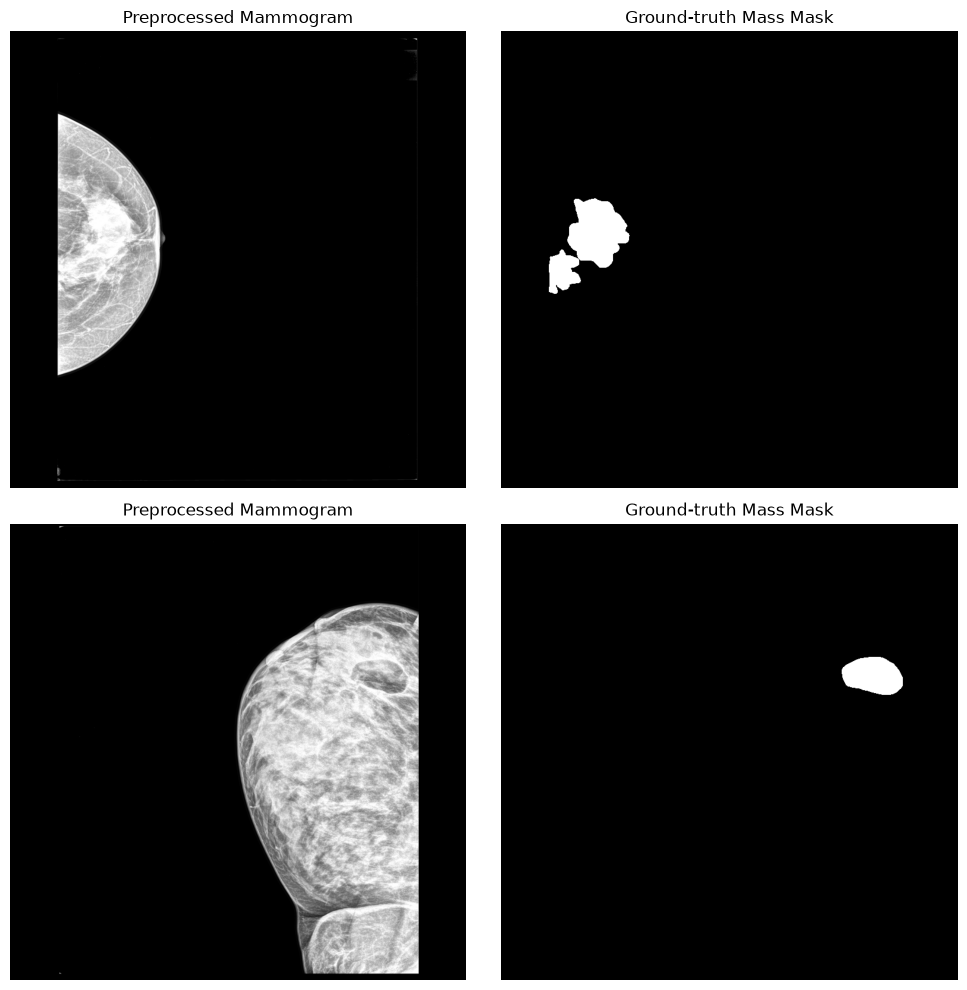

In [45]:
images, masks = next(iter(train_loader))

print("Image shape:", images.shape)
print("Mask shape:", masks.shape)
print("Mask values:", torch.unique(masks))

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for i in range(min(2, len(images))):

    image = images[i].cpu().numpy().transpose(1, 2, 0)

    # Reverse ImageNet normalization for display
    image = image * np.array([0.229, 0.224, 0.225])
    image = image + np.array([0.485, 0.456, 0.406])

    image = np.clip(image, 0, 1)

    axes[i, 0].imshow(image[:, :, 0], cmap="gray")
    axes[i, 0].set_title("Preprocessed Mammogram")

    axes[i, 1].imshow(masks[i, 0].cpu(), cmap="gray")
    axes[i, 1].set_title("Ground-truth Mass Mask")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [46]:
class BCEDiceLoss(nn.Module):

    def __init__(self):
        super().__init__()

    def forward(self, logits, targets):

        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets
        )

        probabilities = torch.sigmoid(logits)

        smooth = 1e-6

        intersection = (
            probabilities * targets
        ).sum(dim=(1, 2, 3))

        denominator = (
            probabilities.sum(dim=(1, 2, 3))
            + targets.sum(dim=(1, 2, 3))
        )

        dice = (
            2 * intersection + smooth
        ) / (
            denominator + smooth
        )

        dice_loss = 1 - dice.mean()

        return 0.5 * bce + 0.5 * dice_loss


def calculate_metrics(logits, targets, threshold=0.5):

    predictions = torch.sigmoid(logits) >= threshold
    targets = targets >= 0.5

    predictions = predictions.float()
    targets = targets.float()

    dims = (1, 2, 3)

    intersection = (predictions * targets).sum(dim=dims)

    pred_sum = predictions.sum(dim=dims)
    target_sum = targets.sum(dim=dims)

    dice = (
        2 * intersection + 1e-7
    ) / (
        pred_sum + target_sum + 1e-7
    )

    union = (
        pred_sum + target_sum - intersection
    )

    iou = (
        intersection + 1e-7
    ) / (
        union + 1e-7
    )

    precision = (
        intersection + 1e-7
    ) / (
        pred_sum + 1e-7
    )

    recall = (
        intersection + 1e-7
    ) / (
        target_sum + 1e-7
    )

    return {
        "dice": dice.mean().item(),
        "iou": iou.mean().item(),
        "precision": precision.mean().item(),
        "recall": recall.mean().item()
    }

In [47]:
model = ResNet18UNet(
    pretrained=True
).to(DEVICE)

criterion = BCEDiceLoss()

encoder_params = []
decoder_params = []

for name, parameter in model.named_parameters():

    if not parameter.requires_grad:
        continue

    if (
        name.startswith("conv1")
        or name.startswith("bn1")
        or name.startswith("layer")
    ):
        encoder_params.append(parameter)
    else:
        decoder_params.append(parameter)

optimizer = torch.optim.AdamW(
    [
        {
            "params": encoder_params,
            "lr": 1e-5
        },
        {
            "params": decoder_params,
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

print("Model initialized.")
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Model initialized.
Trainable parameters: 14343425


In [48]:
def run_epoch(model, loader, optimizer=None):

    training = optimizer is not None

    model.train() if training else model.eval()

    total_loss = 0.0
    metric_totals = {
        "dice": 0.0,
        "iou": 0.0,
        "precision": 0.0,
        "recall": 0.0
    }

    total_samples = 0

    for images, masks in loader:

        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):

                logits = model(images)

                loss = criterion(logits, masks)

            if training:

                scaler.scale(loss).backward()

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                scaler.step(optimizer)
                scaler.update()

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size

        metrics = calculate_metrics(
            logits.detach(),
            masks
        )

        for key in metric_totals:
            metric_totals[key] += metrics[key] * batch_size

        total_samples += batch_size

    results = {
        key: value / total_samples
        for key, value in metric_totals.items()
    }

    results["loss"] = total_loss / total_samples

    return results

In [49]:
EPOCHS = 50
PATIENCE = 10

best_val_dice = -1
epochs_without_improvement = 0

history = []

best_checkpoint = CHECKPOINT_DIR / "dmid_resnet18_unet_best.pt"

for epoch in range(1, EPOCHS + 1):

    train_metrics = run_epoch(
        model,
        train_loader,
        optimizer
    )

    val_metrics = run_epoch(
        model,
        val_loader
    )

    scheduler.step(val_metrics["dice"])

    current_lr_encoder = optimizer.param_groups[0]["lr"]
    current_lr_decoder = optimizer.param_groups[1]["lr"]

    record = {
        "epoch": epoch,
        **{
            f"train_{k}": v
            for k, v in train_metrics.items()
        },
        **{
            f"val_{k}": v
            for k, v in val_metrics.items()
        },
        "encoder_lr": current_lr_encoder,
        "decoder_lr": current_lr_decoder
    }

    history.append(record)

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Dice: {train_metrics['dice']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Dice: {val_metrics['dice']:.4f} | "
        f"Val IoU: {val_metrics['iou']:.4f}"
    )

    if val_metrics["dice"] > best_val_dice:

        best_val_dice = val_metrics["dice"]

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_dice": best_val_dice,
                "history": history,
                "image_size": IMAGE_SIZE,
                "architecture": "ResNet18-UNet"
            },
            best_checkpoint
        )

        print("  Best checkpoint saved.")

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("Early stopping triggered.")
        break

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

print("\nTraining completed.")
print("Best validation Dice:", best_val_dice)
print("Checkpoint:", best_checkpoint)

Epoch [01/50] Train Loss: 0.7820 | Train Dice: 0.1826 | Val Loss: 0.7336 | Val Dice: 0.3203 | Val IoU: 0.2290
  Best checkpoint saved.
Epoch [02/50] Train Loss: 0.7151 | Train Dice: 0.4081 | Val Loss: 0.7036 | Val Dice: 0.3961 | Val IoU: 0.2973
  Best checkpoint saved.
Epoch [03/50] Train Loss: 0.6966 | Train Dice: 0.4571 | Val Loss: 0.6844 | Val Dice: 0.4163 | Val IoU: 0.3232
  Best checkpoint saved.
Epoch [04/50] Train Loss: 0.6826 | Train Dice: 0.4706 | Val Loss: 0.6692 | Val Dice: 0.4219 | Val IoU: 0.3219
  Best checkpoint saved.
Epoch [05/50] Train Loss: 0.6678 | Train Dice: 0.5023 | Val Loss: 0.6590 | Val Dice: 0.4262 | Val IoU: 0.3247
  Best checkpoint saved.
Epoch [06/50] Train Loss: 0.6544 | Train Dice: 0.5062 | Val Loss: 0.6454 | Val Dice: 0.4536 | Val IoU: 0.3475
  Best checkpoint saved.
Epoch [07/50] Train Loss: 0.6421 | Train Dice: 0.5281 | Val Loss: 0.6448 | Val Dice: 0.4188 | Val IoU: 0.3007
Epoch [08/50] Train Loss: 0.6296 | Train Dice: 0.5499 | Val Loss: 0.6206 | Val D

In [50]:
checkpoint = torch.load(
    best_checkpoint,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

test_metrics = run_epoch(
    model,
    test_loader
)

print("\nProvisional Test Results")

for key, value in test_metrics.items():
    print(f"{key}: {value:.4f}")

pd.DataFrame([test_metrics]).to_csv(
    OUTPUT_DIR / "provisional_test_results.csv",
    index=False
)


Provisional Test Results
dice: 0.6445
iou: 0.5452
precision: 0.6833
recall: 0.7118
loss: 0.3566


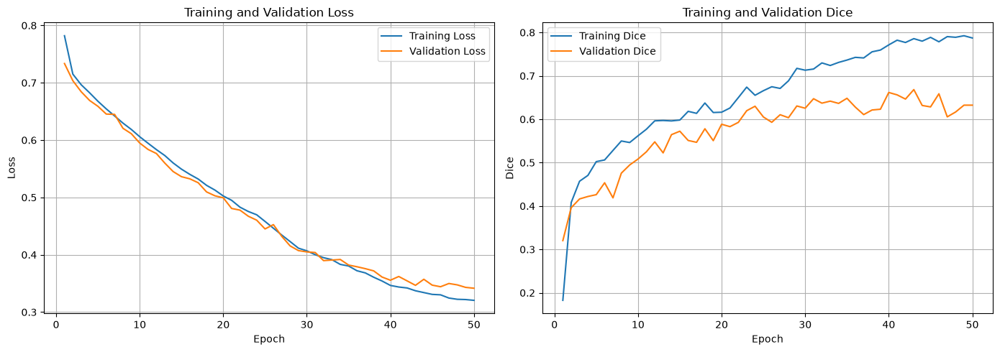

In [51]:
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_df["epoch"],
    history_df["train_dice"],
    label="Training Dice"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_dice"],
    label="Validation Dice"
)

axes[1].set_title("Training and Validation Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

best_checkpoint = (
    "task3_segmentation/checkpoints/dmid_resnet18_unet_best.pt"
)

checkpoint = torch.load(
    best_checkpoint,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation Dice:", checkpoint["best_val_dice"])
print("Model loaded successfully.")

Best epoch: 43
Best validation Dice: 0.668352697044611
Model loaded successfully.


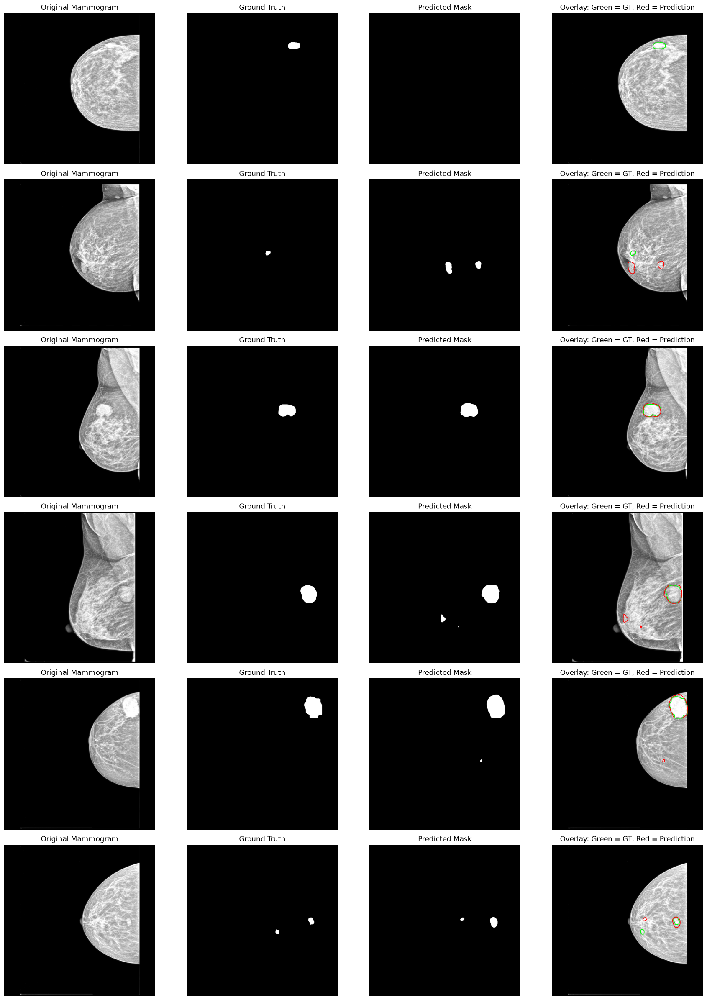

In [53]:
def visualize_predictions(model, loader, num_samples=6):

    model.eval()

    images_list = []
    masks_list = []
    predictions_list = []

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(DEVICE)

            logits = model(images)

            predictions = (
                torch.sigmoid(logits) > 0.5
            ).float()

            for i in range(images.shape[0]):

                images_list.append(images[i].cpu())
                masks_list.append(masks[i].cpu())
                predictions_list.append(predictions[i].cpu())

                if len(images_list) >= num_samples:
                    break

            if len(images_list) >= num_samples:
                break

    n = len(images_list)

    fig, axes = plt.subplots(
        n, 4,
        figsize=(18, 4 * n)
    )

    if n == 1:
        axes = axes[None, :]

    for i in range(n):

        image = images_list[i].numpy().transpose(1, 2, 0)

        # Reverse ImageNet normalization
        image = image * np.array([0.229, 0.224, 0.225])
        image = image + np.array([0.485, 0.456, 0.406])
        image = np.clip(image, 0, 1)

        gt = masks_list[i][0].numpy()
        pred = predictions_list[i][0].numpy()

        axes[i, 0].imshow(image[:, :, 0], cmap="gray")
        axes[i, 0].set_title("Original Mammogram")

        axes[i, 1].imshow(gt, cmap="gray")
        axes[i, 1].set_title("Ground Truth")

        axes[i, 2].imshow(pred, cmap="gray")
        axes[i, 2].set_title("Predicted Mask")

        axes[i, 3].imshow(image[:, :, 0], cmap="gray")
        axes[i, 3].contour(
            gt,
            levels=[0.5],
            colors="lime",
            linewidths=1
        )
        axes[i, 3].contour(
            pred,
            levels=[0.5],
            colors="red",
            linewidths=1
        )
        axes[i, 3].set_title(
            "Overlay: Green = GT, Red = Prediction"
        )

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()

    os.makedirs("task3_segmentation/results", exist_ok=True)

    plt.savefig(
        "task3_segmentation/results/prediction_visualization.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


visualize_predictions(
    model,
    test_loader,
    num_samples=6
)

In [54]:
def evaluate_segmentation(model, loader):

    model.eval()

    results = []

    with torch.no_grad():

        for batch_idx, (images, masks) in enumerate(loader):

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            logits = model(images)

            predictions = (
                torch.sigmoid(logits) >= 0.5
            ).float()

            for i in range(images.shape[0]):

                pred = predictions[i]
                gt = masks[i]

                tp = (pred * gt).sum().item()
                fp = (pred * (1 - gt)).sum().item()
                fn = ((1 - pred) * gt).sum().item()
                tn = ((1 - pred) * (1 - gt)).sum().item()

                dice = (
                    2 * tp / (2 * tp + fp + fn + 1e-8)
                )

                iou = (
                    tp / (tp + fp + fn + 1e-8)
                )

                precision = (
                    tp / (tp + fp + 1e-8)
                )

                recall = (
                    tp / (tp + fn + 1e-8)
                )

                f1 = (
                    2 * precision * recall /
                    (precision + recall + 1e-8)
                )

                results.append({
                    "dice": dice,
                    "iou": iou,
                    "precision": precision,
                    "recall": recall,
                    "f1": f1
                })

    return pd.DataFrame(results)


test_results_df = evaluate_segmentation(
    model,
    test_loader
)

print("Individual test results:")
print(test_results_df.head(10))

print("\nOverall test performance:")
print(test_results_df.mean())

test_results_df.to_csv(
    "task3_segmentation/results/test_metrics_per_image.csv",
    index=False
)

test_results_df.mean().to_csv(
    "task3_segmentation/results/test_metrics_summary.csv"
)

print("Evaluation completed.")

Individual test results:
       dice       iou  precision    recall        f1
0  0.000000  0.000000   0.000000  0.000000  0.000000
1  0.000000  0.000000   0.000000  0.000000  0.000000
2  0.922243  0.855705   0.867732  0.984061  0.922243
3  0.881207  0.787641   0.793122  0.991303  0.881207
4  0.924086  0.858885   0.867929  0.988013  0.924086
5  0.523951  0.354969   0.425886  0.680687  0.523951
6  0.617679  0.446842   0.778537  0.511910  0.617679
7  0.000000  0.000000   0.000000  0.000000  0.000000
8  0.893889  0.808137   0.843291  0.950946  0.893889
9  0.693458  0.530759   0.800120  0.611889  0.693458

Overall test performance:
dice         0.645622
iou          0.546458
precision    0.636225
recall       0.712126
f1           0.645622
dtype: float64
Evaluation completed.


In [55]:
import copy
from collections import OrderedDict

def calculate_fisher(
    model,
    loader,
    max_samples=None
):

    model.eval()

    fisher = OrderedDict()

    for name, parameter in model.named_parameters():

        if parameter.requires_grad:
            fisher[name] = torch.zeros_like(
                parameter,
                device=parameter.device
            )

    sample_count = 0

    for images, masks in loader:

        for i in range(images.size(0)):

            if (
                max_samples is not None
                and sample_count >= max_samples
            ):
                break

            image = images[i:i+1].to(DEVICE)
            mask = masks[i:i+1].to(DEVICE)

            model.zero_grad(set_to_none=True)

            logits = model(image)

            loss = criterion(logits, mask)

            loss.backward()

            for name, parameter in model.named_parameters():

                if (
                    parameter.requires_grad
                    and parameter.grad is not None
                ):

                    fisher[name] += (
                        parameter.grad.detach() ** 2
                    )

            sample_count += 1

        if (
            max_samples is not None
            and sample_count >= max_samples
        ):
            break

    # Average over individual samples
    for name in fisher:
        fisher[name] /= max(sample_count, 1)

    model.zero_grad(set_to_none=True)

    return fisher, sample_count


fisher_information, fisher_sample_count = calculate_fisher(
    model,
    train_loader,
    max_samples=None
)

print("Fisher samples:", fisher_sample_count)

all_fisher_values = torch.cat([
    value.detach().flatten().cpu()
    for value in fisher_information.values()
])

print("Fisher statistics")
print("Mean:", all_fisher_values.mean().item())
print("Maximum:", all_fisher_values.max().item())
print("Minimum:", all_fisher_values.min().item())
print(
    "Non-zero:",
    torch.count_nonzero(all_fisher_values).item()
)

Fisher samples: 188
Fisher statistics
Mean: 4.5370625230134465e-06
Maximum: 0.2782050371170044
Minimum: 0.0
Non-zero: 14332724


In [56]:
theta_star = {
    name: parameter.detach().cpu().clone()
    for name, parameter in model.named_parameters()
}

fisher_cpu = {
    name: value.detach().cpu().clone()
    for name, value in fisher_information.items()
}

task3_checkpoint = {

    "task_name": "DMID Mass Segmentation",

    "architecture": "ResNet18-UNet",

    "model_state_dict": {
        name: value.detach().cpu().clone()
        for name, value in model.state_dict().items()
    },

    "fisher_information": fisher_cpu,

    "theta_star": theta_star,

    "fisher_sample_count": fisher_sample_count,

    "test_results": test_results_df.mean().to_dict(),

    "training_history": history,

    "hyperparameters": {
        "image_size": IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "optimizer": "AdamW",
        "encoder_lr": 1e-5,
        "decoder_lr": 1e-4,
        "weight_decay": 1e-4,
        "epochs": EPOCHS,
        "loss": "0.5 BCE + 0.5 Dice",
        "architecture": "ResNet18-UNet"
    }
}

task3_path = (
    "task3_segmentation/final_task3/"
    "task3_dmid_segmentation_with_fisher.pt"
)

os.makedirs(
    os.path.dirname(task3_path),
    exist_ok=True
)

torch.save(
    task3_checkpoint,
    task3_path
)

print("Task 3 checkpoint saved:")
print(task3_path)

Task 3 checkpoint saved:
task3_segmentation/final_task3/task3_dmid_segmentation_with_fisher.pt


In [57]:
saved_checkpoint = torch.load(
    task3_path,
    map_location="cpu",
    weights_only=False
)

print("Task:", saved_checkpoint["task_name"])

print(
    "Architecture:",
    saved_checkpoint["architecture"]
)

print(
    "Fisher samples:",
    saved_checkpoint["fisher_sample_count"]
)

print(
    "Number of Fisher parameter tensors:",
    len(saved_checkpoint["fisher_information"])
)

print(
    "Test results:",
    saved_checkpoint["test_results"]
)

print("\nTask 3 checkpoint verified.")

Task: DMID Mass Segmentation
Architecture: ResNet18-UNet
Fisher samples: 188
Number of Fisher parameter tensors: 102
Test results: {'dice': 0.6456215084577364, 'iou': 0.5464576625662575, 'precision': 0.6362249526245856, 'recall': 0.7121258686175751, 'f1': 0.6456215043152853}

Task 3 checkpoint verified.
